# 2.1 Forecasting: regional electricity demand

**Question.** How well can monthly household electricity use be forecast for each of the 11 SERL regions, does weather help, and what does 2024 look like?

**Data.** SERL cleaned daily-statistics file (monthly rows, 2020–2023), read with `serl_energy.dataset`. Target: **Electricity net, kWh/day, all households in the region** (all heating fuels, with and without PV, all days), one consistent 48-month series per region. Weather: SERL's own region-matched temperature and heating degree days (HDD).

**Method.** Seasonal naive, ETS, SARIMA and SARIMAX with HDD, compared in a rolling-origin backtest (5 folds × 11 regions × 12 months ahead) with MAE, RMSE, MAPE and MASE, and Wilcoxon tests on region-level MASE. Residual checks (Ljung–Box). The best usable model forecasts 2024 with 80% and 95% intervals.

**Outputs.** Figures in `reports/figures/2.1-forecasting-regional/`, tables in `reports/tables/2.1-forecasting-regional/`. The appendix keeps the unused Open-Meteo and Google Trends clients.


## 1. Data: one consistent series per region

Each SERL row is one group of households in one unit, so a region's series fixes the quantity, unit, weekday/weekend, heating fuel and PV status (`serl_energy.dataset` raises an error if any row is duplicated). An earlier version did not fix the unit, so each region's "series" stacked three units (144 points instead of 48), which produced errors of about 1,500% MAPE.

**Look for:** every region follows the same seasonal shape and the same fall in 2022; Scotland and the North East fell most.


48 months x 11 regions, 0 missing values

Electricity net (kWh/day) by region
                 mean_kwh_per_day  min_kwh_per_day  max_kwh_per_day  mean_2020  mean_2023  change_2020_2023_pct
region                                                                                                         
South East                   9.89             6.87            14.60      10.64       8.95                -15.89
Greater London               9.61             6.60            14.39      10.52       8.56                -18.64
East of England              9.60             6.37            14.76      10.68       8.48                -20.56
Scotland                     9.43             5.91            15.70      12.06       7.82                -35.18
South West                   9.15             5.60            14.22      10.32       8.23                -20.22
North West                   9.09             6.16            13.40      10.45       7.99                -23.57
East Midlands             

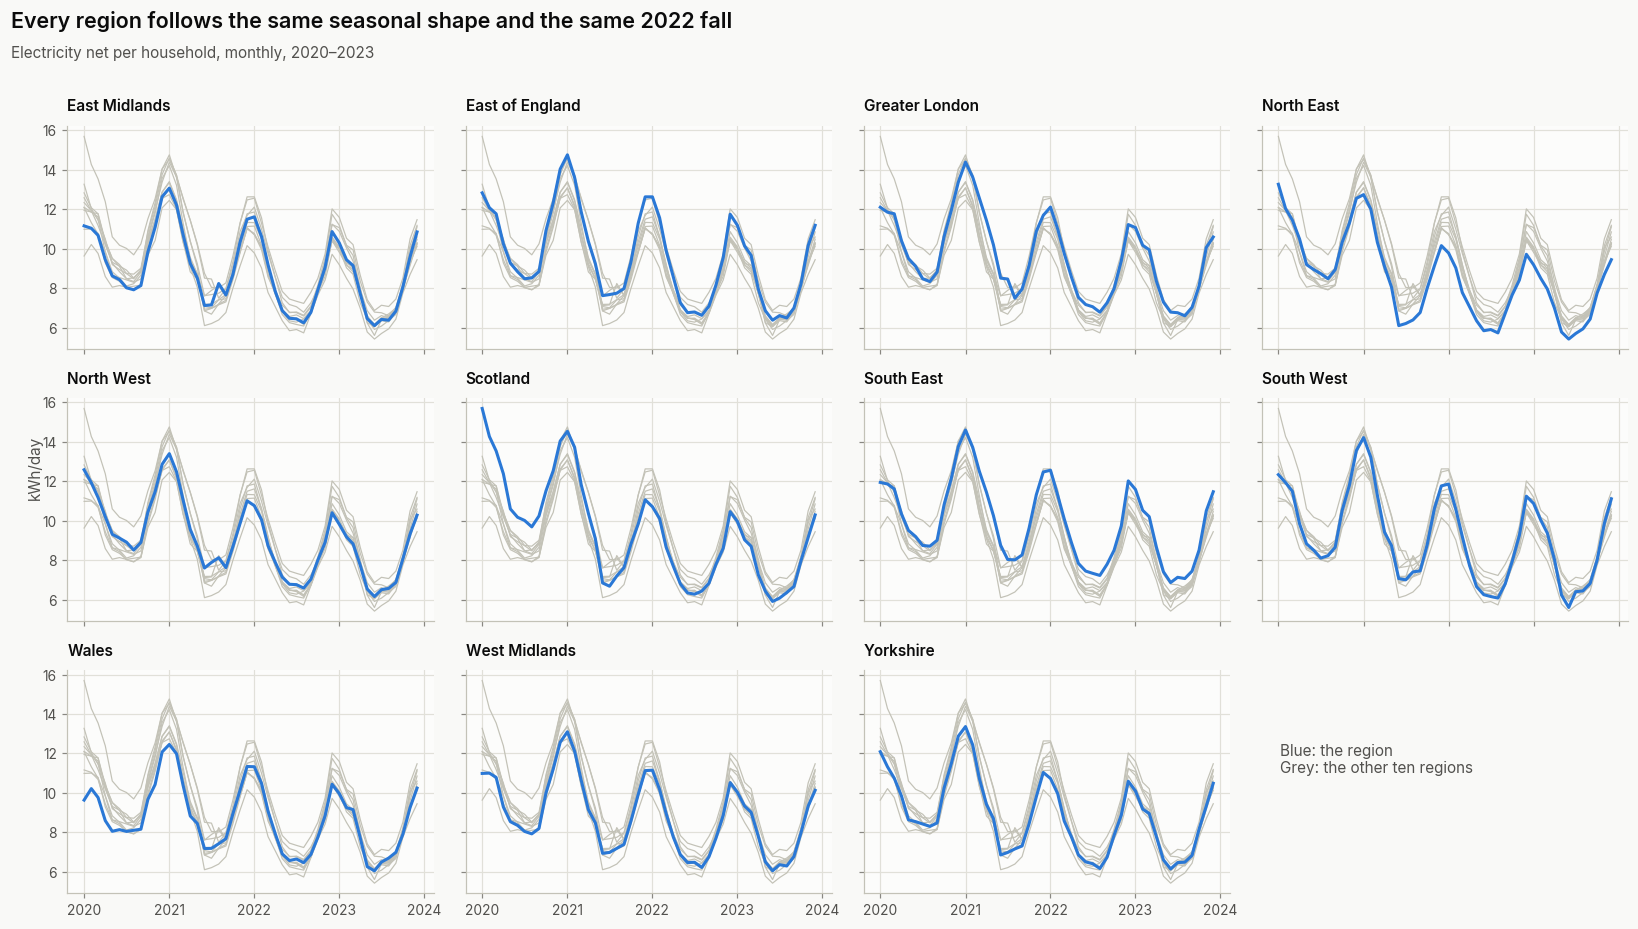

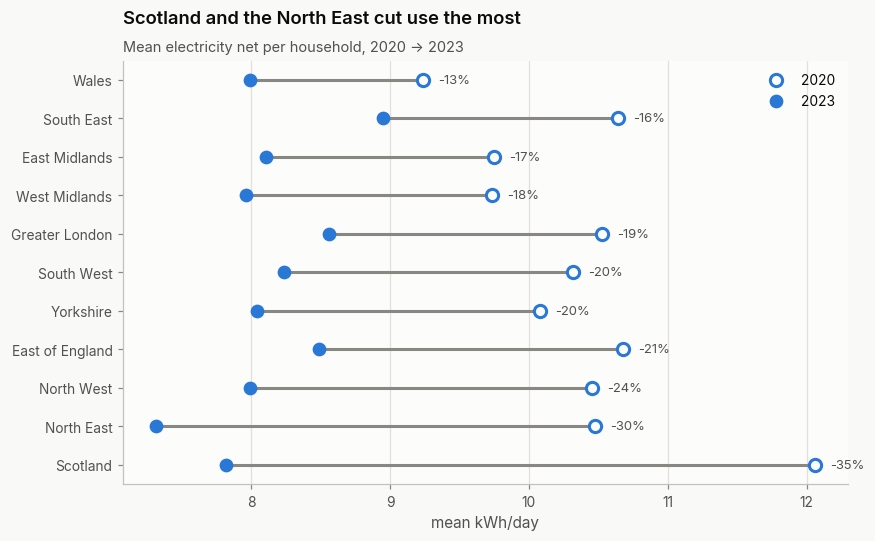

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tools.sm_exceptions import ConvergenceWarning

from serl_energy import dataset as serl, plots
from serl_energy.plots import CATEGORICAL, COLORS, DIVERGING_CMAP, INK, SEQUENTIAL_CMAP
from serl_energy.reporting import Reporter

warnings.filterwarnings("ignore", category=ConvergenceWarning)  # optimiser notes on short series
warnings.filterwarnings("ignore", category=UserWarning)
plots.use_theme()
reporter = Reporter("2.1-forecasting-regional")

QUANTITY, UNIT = "Electricity net", "kWh/day"
monthly = serl.load_monthly(serl.CLEAN_CSV)
Y = serl.monthly_panel(monthly, QUANTITY, UNIT, "region")                       # 48 months x 11 regions
HDD = serl.monthly_panel(monthly, QUANTITY, UNIT, "region", value="mean_hdd")   # heating degree days per day
TEMP = serl.monthly_panel(monthly, QUANTITY, UNIT, "region", value="mean_temp")
SOLAR = serl.monthly_panel(monthly, QUANTITY, UNIT, "region", value="mean_solar")
for panel in (Y, HDD, TEMP, SOLAR):
    panel.columns.name = "region"
print(f"{Y.shape[0]} months x {Y.shape[1]} regions, {Y.isna().sum().sum()} missing values")

summary = pd.DataFrame({"mean_kwh_per_day": Y.mean(), "min_kwh_per_day": Y.min(), "max_kwh_per_day": Y.max(),
                        "mean_2020": Y.loc["2020"].mean(), "mean_2023": Y.loc["2023"].mean()})
summary["change_2020_2023_pct"] = 100 * (summary["mean_2023"] / summary["mean_2020"] - 1)
summary = summary.sort_values("mean_kwh_per_day", ascending=False)
print(f"\n{QUANTITY} ({UNIT}) by region")
print(summary.round(2).to_string())
reporter.save_table(summary, "region_summary", index=True)

fig, axes = plt.subplots(3, 4, figsize=(15, 8.5), sharex=True, sharey=True)
for ax, region in zip(axes.flat, Y.columns):
    for other in Y.columns:
        ax.plot(Y.index, Y[other], color=COLORS["axis"], lw=0.8, zorder=1)
    ax.plot(Y.index, Y[region], color=COLORS["electricity"], lw=2, zorder=2)
    ax.set_title(region, loc="left", fontsize=10)
    plots.year_axis(ax)
ax = axes.flat[-1]
ax.axis("off")
ax.text(0.05, 0.6, "Blue: the region\nGrey: the other ten regions", transform=ax.transAxes, fontsize=10,
        color=INK["secondary"], va="center")
fig.supylabel(UNIT, color=INK["secondary"], fontsize=10)
plots.figure_title(fig, "Every region follows the same seasonal shape and the same 2022 fall",
                   f"{QUANTITY} per household, monthly, 2020–2023")
reporter.save_fig(fig, "regional-series-small-multiples")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5))
s = summary.sort_values("change_2020_2023_pct")
pos = np.arange(len(s))
ax.hlines(pos, s["mean_2023"], s["mean_2020"], color=INK["muted"], lw=2)
ax.scatter(s["mean_2020"], pos, color=COLORS["surface"], edgecolor=COLORS["electricity"], linewidth=2, s=64,
           zorder=3, label="2020")
ax.scatter(s["mean_2023"], pos, color=COLORS["electricity"], s=64, zorder=3, label="2023")
for p, (_, r) in zip(pos, s.iterrows()):
    ax.annotate(f"{r['change_2020_2023_pct']:+.0f}%", (r["mean_2020"], p), xytext=(10, 0), textcoords="offset points",
                va="center", fontsize=8.5, color=INK["secondary"])
ax.set_yticks(pos, s.index); ax.grid(axis="y", visible=False); ax.set_xlabel("mean kWh/day")
ax.legend(loc="upper right")
plots.title(ax, "Scotland and the North East cut use the most", "Mean electricity net per household, 2020 → 2023")
reporter.save_fig(fig, "regional-change-dumbbell")
plt.show()

## 2. Seasonality and weather

The heatmap shows each month relative to the region's own average: red above, blue below. Seasonal strength comes from an STL decomposition (0 = no seasonality, 1 = almost entirely seasonal). The weather table explains why only heating degree days are used as a weather input: no month is warm enough for cooling degree days (base 22 °C) to be above zero.


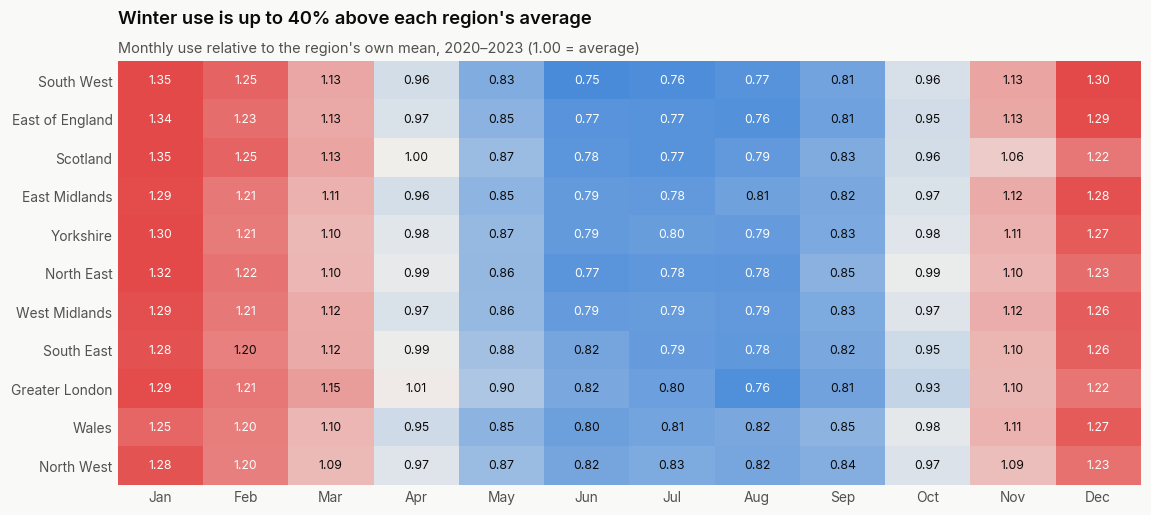

                 seasonal_strength  winter_to_summer  spearman_hdd  spearman_solar
region                                                                            
South West                    0.91              1.72          0.86           -0.78
East of England               0.90              1.68          0.87           -0.75
Scotland                      0.92              1.64          0.75           -0.61
North East                    0.92              1.62          0.76           -0.65
East Midlands                 0.90              1.59          0.87           -0.78
Yorkshire                     0.88              1.59          0.86           -0.74
West Midlands                 0.84              1.59          0.88           -0.77
Greater London                0.84              1.56          0.88           -0.65
South East                    0.85              1.56          0.88           -0.72
Wales                         0.84              1.52          0.85           -0.79
Nort

In [2]:
from statsmodels.tsa.seasonal import STL

MONTHS = "Jan Feb Mar Apr May Jun Jul Aug Sep Oct Nov Dec".split()
relative = Y.div(Y.mean())
by_month = relative.groupby(relative.index.month).mean().T
by_month = by_month.loc[by_month[[12, 1, 2]].mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(by_month, aspect="auto", cmap=DIVERGING_CMAP, vmin=0.7, vmax=1.3)
for (i, j), v in np.ndenumerate(by_month.to_numpy()):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
            color=COLORS["surface"] if abs(v - 1) > 0.2 else INK["primary"])
ax.set_xticks(range(12), MONTHS); ax.set_yticks(range(len(by_month)), by_month.index)
ax.grid(False); ax.tick_params(length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plots.title(ax, "Winter use is up to 40% above each region's average",
            "Monthly use relative to the region's own mean, 2020–2023 (1.00 = average)")
reporter.save_fig(fig, "regional-seasonality-heatmap")
plt.show()


def seasonal_strength(y):
    res = STL(y, period=12, robust=True).fit()
    return max(0.0, 1 - np.var(res.resid) / np.var(res.seasonal + res.resid))


season = pd.DataFrame({
    "seasonal_strength": Y.apply(seasonal_strength),
    "winter_to_summer": Y[Y.index.month.isin([12, 1, 2])].mean() / Y[Y.index.month.isin([6, 7, 8])].mean(),
    "spearman_hdd": [Y[r].corr(HDD[r], method="spearman") for r in Y.columns],
    "spearman_solar": [Y[r].corr(SOLAR[r], method="spearman") for r in Y.columns],
}).sort_values("winter_to_summer", ascending=False)
print(season.round(2).to_string())
reporter.save_table(season, "seasonality_by_region", index=True)

weather = pd.DataFrame({
    "mean_temp_c": TEMP.mean(axis=1).groupby(TEMP.index.month).mean(),
    "warmest_region_temp_c": TEMP.max(axis=1).groupby(TEMP.index.month).max(),
    "hdd_per_day": HDD.mean(axis=1).groupby(HDD.index.month).mean(),
})
weather["cdd_per_day_base22"] = (weather["warmest_region_temp_c"] - 22).clip(lower=0)
weather.index.name = "month"
print("\nWeather by calendar month, 2020–2023 (monthly means across regions)")
print(weather.round(2).to_string())
reporter.save_table(weather, "weather_by_month", index=True)

## 3. Models and rolling-origin evaluation

| Model | Description |
|---|---|
| Seasonal naive | Next year's month = this year's same month (baseline) |
| ETS | Additive damped trend + additive seasonality (Holt–Winters) |
| SARIMA | (1,0,0)(0,1,1)₁₂ |
| SARIMAX + HDD (ex-ante) | SARIMA + heating degree days; future HDD = average of the same calendar month in the training data (what is known when forecasting) |
| SARIMAX + HDD (ex-post) | Same model given the actual future HDD; an upper bound showing what a perfect weather forecast would add |

Fixed, low orders are used because 24–36 training months are too few to select orders reliably.

**Backtest.** For every region, models are trained on the first 24, 27, 30, 33 and 36 months and forecast the next 12 (5 folds × 11 regions). Errors: MAE and RMSE in kWh/day, MAPE, and MASE (MAE divided by the in-sample error of the seasonal naive forecast; below 1 beats the naive benchmark). Models are compared with a Wilcoxon signed-rank test on region-level MASE (11 paired values).


In [3]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

H = 12
ORIGINS = range(24, Y.shape[0] - H + 1, 3)       # 24, 27, 30, 33, 36 training months


def climatology(x_train, index):
    """Future exogenous values = mean of the same calendar month in the training data."""
    by_month = x_train.groupby(x_train.index.month).mean()
    return pd.DataFrame({x_train.name: by_month.reindex(index.month).to_numpy()}, index=index)


def seasonal_naive(y, h, **_):
    return np.tile(y.iloc[-12:].to_numpy(), h // 12 + 1)[:h]


def ets(y, h, **_):
    fit = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit()
    return fit.forecast(h).to_numpy()


def sarima(y, h, **_):
    return SARIMAX(y, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(h).to_numpy()


def sarimax_hdd(y, h, x_train, x_future):
    fit = SARIMAX(y, exog=x_train, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
    return fit.forecast(h, exog=x_future).to_numpy()


MODELS = {"Seasonal naive": seasonal_naive, "ETS": ets, "SARIMA": sarima,
          "SARIMAX + HDD (ex-ante)": sarimax_hdd, "SARIMAX + HDD (ex-post)": sarimax_hdd}
# one colour per model, fixed for every chart in this notebook (naive = muted reference)
MODEL_STYLE = {"Seasonal naive": (INK["muted"], "-"), "ETS": (CATEGORICAL[0], "-"), "SARIMA": (CATEGORICAL[6], "-"),
               "SARIMAX + HDD (ex-ante)": (CATEGORICAL[2], "-"), "SARIMAX + HDD (ex-post)": (CATEGORICAL[2], "--")}

rows = []
for region in Y.columns:
    y, x = Y[region], HDD[region]
    for origin in ORIGINS:
        train, test = y.iloc[:origin], y.iloc[origin:origin + H]
        scale = np.mean(np.abs(train.to_numpy()[12:] - train.to_numpy()[:-12]))   # seasonal-naive in-sample MAE
        x_train = x.iloc[:origin].to_frame()
        future = {"ex-ante": climatology(x.iloc[:origin], test.index), "ex-post": x.iloc[origin:origin + H].to_frame()}
        for name, model in MODELS.items():
            x_future = future["ex-post"] if "ex-post" in name else future["ex-ante"]
            pred = model(train, H, x_train=x_train, x_future=x_future)
            for step, (actual, p) in enumerate(zip(test.to_numpy(), pred), start=1):
                rows.append({"region": region, "test_start": test.index[0].date(), "model": name, "horizon": step,
                             "actual": actual, "forecast": p, "abs_err": abs(actual - p),
                             "sq_err": (actual - p) ** 2, "scaled_err": abs(actual - p) / scale,
                             "pct_err": abs(actual - p) / actual})
errors = pd.DataFrame(rows)
print(f"{len(errors):,} forecasts: {errors['region'].nunique()} regions x {errors['test_start'].nunique()} folds "
      f"x {errors['model'].nunique()} models x {H} months")

3,300 forecasts: 11 regions x 5 folds x 5 models x 12 months


**Results.** Left: mean MASE per model with the range across regions (lower is better; below the dashed line beats the naive benchmark). Middle: error by months ahead. Right: MASE for every region and model.


Mean (std) over 55 region-folds; MAE/RMSE in kWh/day, MAPE in %
                           mae          rmse        mape_pct          mase       
                          mean    std   mean    std     mean    std   mean    std
model                                                                            
ETS                      0.632  0.360  0.725  0.365    7.842  4.467  0.489  0.268
SARIMAX + HDD (ex-post)  0.620  0.335  0.697  0.337    7.820  4.480  0.496  0.304
SARIMAX + HDD (ex-ante)  0.656  0.337  0.734  0.344    8.281  4.448  0.528  0.323
SARIMA                   0.660  0.278  0.753  0.270    8.273  3.580  0.534  0.285
Seasonal naive           0.797  0.385  0.932  0.425    9.740  4.566  0.656  0.389

Wilcoxon signed-rank tests on region-level MASE (11 pairs)
  ETS                       vs Seasonal naive  : lower MASE in  9/11 regions, p = 0.019
  SARIMA                    vs Seasonal naive  : lower MASE in 10/11 regions, p = 0.003
  SARIMAX + HDD (ex-ante)   vs Seasonal naiv

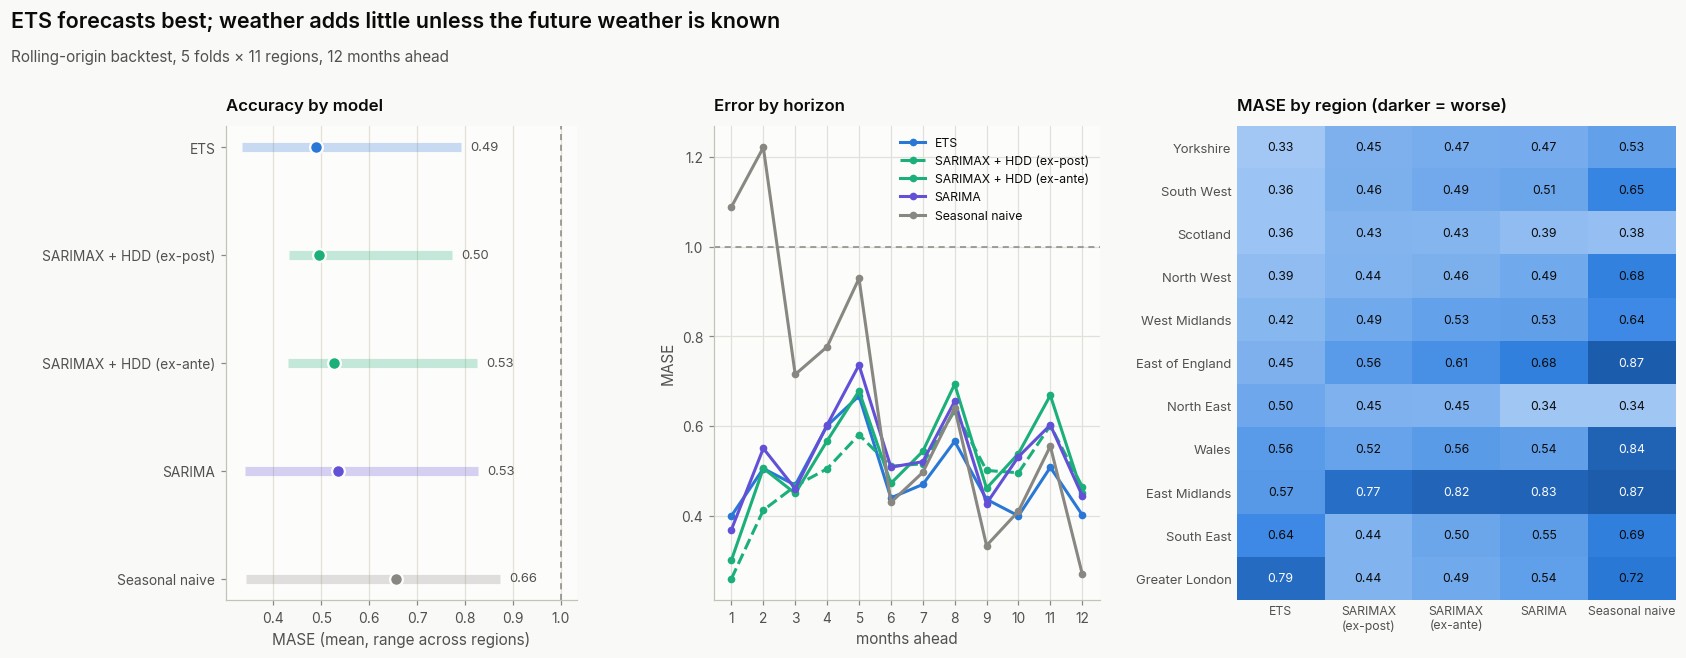

In [4]:
from scipy.stats import wilcoxon

folds = (errors.groupby(["model", "region", "test_start"])
         .agg(mae=("abs_err", "mean"), rmse=("sq_err", lambda s: np.sqrt(s.mean())),
              mase=("scaled_err", "mean"), mape_pct=("pct_err", lambda s: 100 * s.mean()))
         .reset_index())
leaderboard = folds.groupby("model")[["mae", "rmse", "mape_pct", "mase"]].agg(["mean", "std"]).sort_values(("mase", "mean"))
print("Mean (std) over 55 region-folds; MAE/RMSE in kWh/day, MAPE in %")
print(leaderboard.round(3).to_string())
reporter.save_table(folds, "forecast_evaluation")

region_mase = folds.groupby(["region", "model"])["mase"].mean().unstack()
print("\nWilcoxon signed-rank tests on region-level MASE (11 pairs)")
pairs = [("ETS", "Seasonal naive"), ("SARIMA", "Seasonal naive"), ("SARIMAX + HDD (ex-ante)", "Seasonal naive"),
         ("ETS", "SARIMA"), ("SARIMAX + HDD (ex-ante)", "SARIMA"), ("SARIMAX + HDD (ex-post)", "SARIMA")]
tests = []
for a, b in pairs:
    tests.append({"model_a": a, "model_b": b, "regions_a_better": int((region_mase[a] < region_mase[b]).sum()),
                  "p_value": wilcoxon(region_mase[a], region_mase[b]).pvalue})
    print(f"  {a:<25} vs {b:<16}: lower MASE in {tests[-1]['regions_a_better']:2d}/11 regions, p = {tests[-1]['p_value']:.3f}")
reporter.save_table(pd.DataFrame(tests), "model_comparison_tests")

order = list(leaderboard.index)
fig = plt.figure(figsize=(17, 5.6))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1.1, 1.25], wspace=0.35)
ax = fig.add_subplot(gs[0])
for i, name in enumerate(order):
    color, _ = MODEL_STYLE[name]
    vals = region_mase[name]
    ax.hlines(i, vals.min(), vals.max(), color=color, lw=6, alpha=0.25)
    ax.scatter(vals.mean(), i, color=color, s=70, zorder=3, edgecolor=COLORS["surface"], linewidth=1.5)
    ax.annotate(f"{vals.mean():.2f}", (vals.max(), i), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=INK["secondary"])
ax.axvline(1, color=INK["muted"], lw=1, ls=(0, (4, 3)))
ax.set_yticks(range(len(order)), order); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("MASE (mean, range across regions)"); ax.set_title("Accuracy by model", loc="left", fontsize=11)

ax = fig.add_subplot(gs[1])
by_h = errors.groupby(["horizon", "model"])["scaled_err"].mean().unstack()
for name in order:
    color, ls = MODEL_STYLE[name]
    ax.plot(by_h.index, by_h[name], color=color, ls=ls, marker="o", markersize=4, label=name)
ax.axhline(1, color=INK["muted"], lw=1, ls=(0, (4, 3)))
ax.set_xlabel("months ahead"); ax.set_ylabel("MASE"); ax.set_xticks(range(1, 13))
ax.set_title("Error by horizon", loc="left", fontsize=11); ax.legend(fontsize=8, loc="upper right")

ax = fig.add_subplot(gs[2])
grid = region_mase[order].sort_values("ETS")
im = ax.imshow(grid, cmap=SEQUENTIAL_CMAP, aspect="auto", vmin=0.2, vmax=1.1)
for (i, j), v in np.ndenumerate(grid.to_numpy()):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
            color=COLORS["surface"] if v > 0.75 else INK["primary"])
ax.set_xticks(range(len(order)), [o.replace("SARIMAX + HDD ", "SARIMAX\n") for o in order], fontsize=8)
ax.set_yticks(range(len(grid)), grid.index, fontsize=8.5); ax.grid(False); ax.tick_params(length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.set_title("MASE by region (darker = worse)", loc="left", fontsize=11)
fig.text(0.01, 1.04, "ETS forecasts best; weather adds little unless the future weather is known",
         fontsize=14, fontweight=plots.TITLE_WEIGHT, color=INK["primary"])
fig.text(0.01, 0.985, "Rolling-origin backtest, 5 folds × 11 regions, 12 months ahead", fontsize=10,
         color=INK["secondary"])
reporter.save_fig(fig, "model-accuracy")
plt.show()

## 4. Residual checks

Each model is fitted to all 48 months of each region, and the Ljung–Box test checks whether the residuals still contain autocorrelation up to lag 12 (p < 0.05 means structure is left unexplained). The first 13 residuals are dropped because seasonal differencing and initialisation make them unreliable.


In [5]:
from statsmodels.stats.diagnostic import acorr_ljungbox


def residuals(name, y, x):
    if name == "ETS":
        return ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit().resid
    exog = x.to_frame() if "HDD" in name else None
    return SARIMAX(y, exog=exog, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False).resid


lb = {}
for name, col in (("ETS", "ets"), ("SARIMA", "sarima"), ("SARIMAX + HDD (ex-ante)", "sarimax_hdd")):
    lb[col] = {region: acorr_ljungbox(residuals(name, Y[region], HDD[region]).iloc[13:], lags=[12])["lb_pvalue"].iloc[0]
               for region in Y.columns}
lb = pd.DataFrame(lb)
lb.index.name = "region"
print("Ljung–Box p-value at lag 12 (full-sample fits)")
print(lb.round(3).to_string())
print("\nRegions with p < 0.05:", {m: int((lb[m] < 0.05).sum()) for m in lb.columns})
reporter.save_table(lb, "ljung_box_pvalues", index=True)

Ljung–Box p-value at lag 12 (full-sample fits)
                   ets  sarima  sarimax_hdd
region                                     
East Midlands    0.053   0.062        0.497
East of England  0.394   0.399        0.599
Greater London   0.485   0.773        0.171
North East       0.496   0.299        0.826
North West       0.392   0.441        0.703
Scotland         0.734   0.192        0.585
South East       0.394   0.441        0.814
South West       0.423   0.277        0.908
Wales            0.654   0.314        0.652
West Midlands    0.530   0.254        0.550
Yorkshire        0.342   0.102        0.297

Regions with p < 0.05: {'ets': 0, 'sarima': 0, 'sarimax_hdd': 0}


## 5. Forecasts for 2024

The model with the lowest mean MASE among those usable in practice (ex-post weather is not available when forecasting) is refitted on all 48 months for each region. Intervals: for ETS, 1,000 simulated future paths; for SARIMA-type models, the model's own forecast intervals. Both assume the model is correct and the 2020–2023 pattern continues. The fan shows the 80% (darker) and 95% (lighter) intervals.


Best usable model by mean MASE: ETS


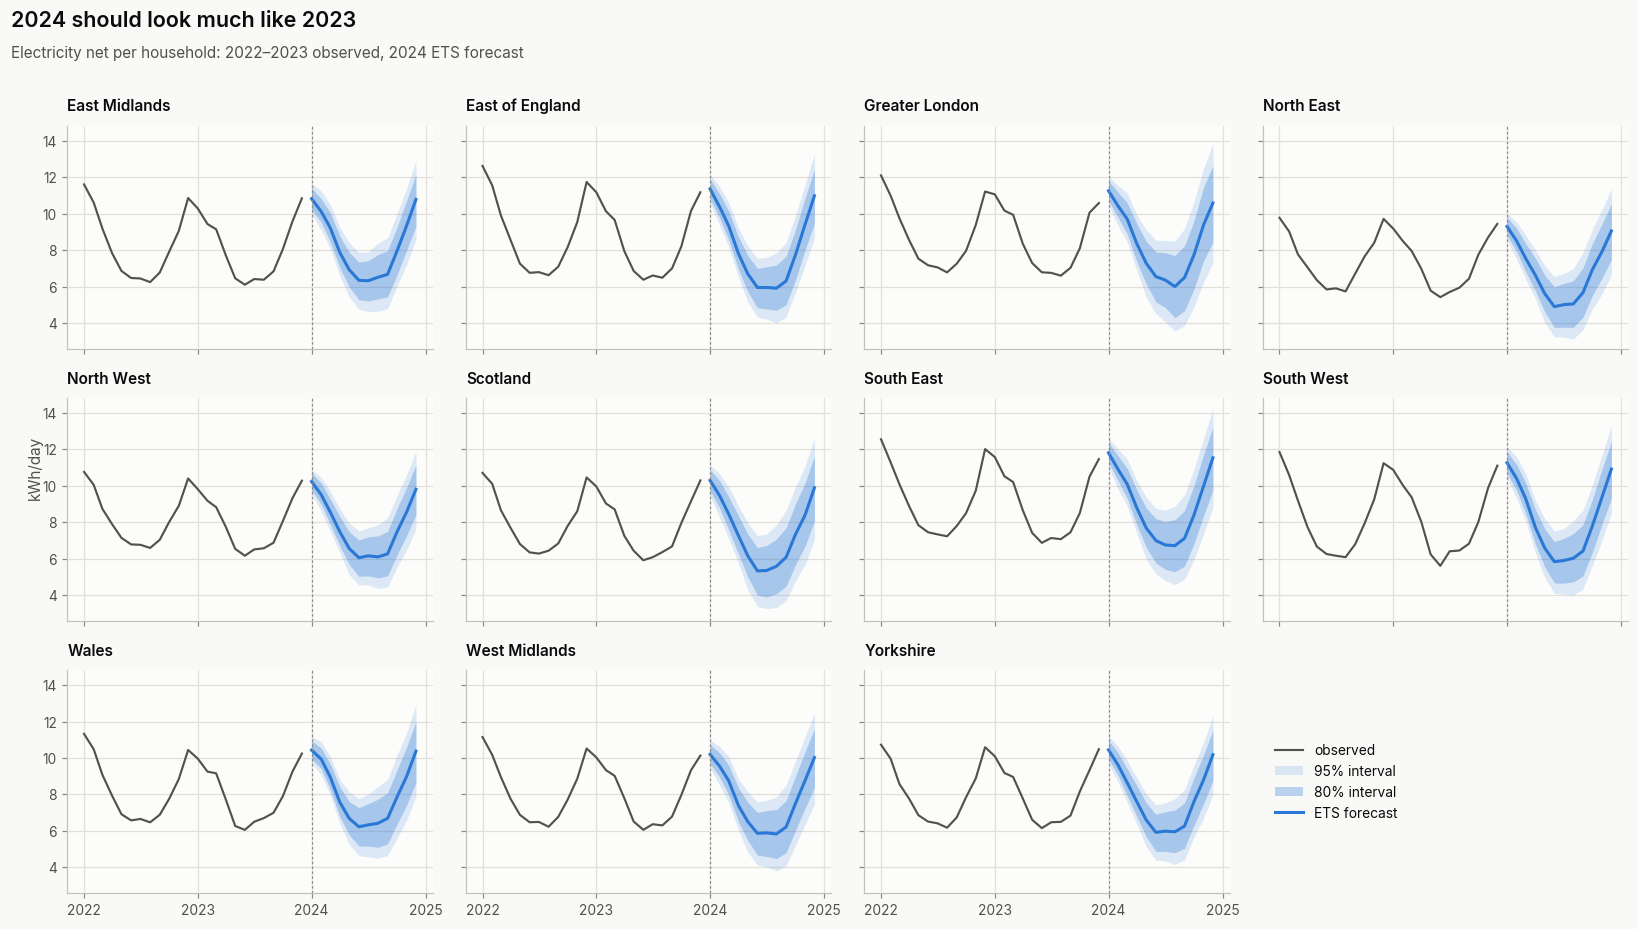

Mean kWh/day: 2023 actual vs 2024 forecast
                 forecast_2024  actual_2023  change_pct
region                                                 
East Midlands             8.24         8.11        1.66
East of England           8.15         8.48       -3.90
Greater London            8.35         8.56       -2.54
North East                6.84         7.31       -6.42
North West                7.73         7.99       -3.31
Scotland                  7.46         7.82       -4.53
South East                8.90         8.95       -0.59
South West                8.13         8.23       -1.28
Wales                     8.03         7.99        0.44
West Midlands             7.70         7.96       -3.30
Yorkshire                 7.79         8.04       -3.09


In [6]:
usable = [m for m in leaderboard.index if "ex-post" not in m and m != "Seasonal naive"]
best = usable[0]
print(f"Best usable model by mean MASE: {best}")

future_index = pd.date_range(Y.index[-1] + pd.offsets.MonthBegin(), periods=H, freq="MS")
out = []
for region in Y.columns:
    y = Y[region]
    if best == "ETS":
        fit = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit()
        sims = fit.simulate(H, repetitions=1000, error="add", random_state=42)
        mean, q = fit.forecast(H).to_numpy(), sims.quantile([0.025, 0.1, 0.9, 0.975], axis=1).T.to_numpy()
    else:
        exog = HDD[region].to_frame() if "HDD" in best else None
        fit = SARIMAX(y, exog=exog, order=(1, 0, 0), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
        x_future = climatology(HDD[region], future_index) if exog is not None else None
        fc = fit.get_forecast(H, exog=x_future)
        mean = fc.predicted_mean.to_numpy()
        q = np.column_stack([fc.conf_int(alpha=0.05).iloc[:, 0], fc.conf_int(alpha=0.2).iloc[:, 0],
                             fc.conf_int(alpha=0.2).iloc[:, 1], fc.conf_int(alpha=0.05).iloc[:, 1]])
    out.append(pd.DataFrame({"region": region, "month": future_index, "forecast_kwh_per_day": mean,
                             "lo95": q[:, 0], "lo80": q[:, 1], "hi80": q[:, 2], "hi95": q[:, 3]}))
forecasts = pd.concat(out, ignore_index=True)
reporter.save_table(forecasts, "forecasts_2024_by_region")

c = COLORS["electricity"]
fig, axes = plt.subplots(3, 4, figsize=(15, 8.5), sharex=True, sharey=True)
for ax, region in zip(axes.flat, Y.columns):
    f = forecasts[forecasts["region"] == region]
    ax.plot(Y.index[-24:], Y[region].iloc[-24:], color=INK["secondary"], lw=1.4, label="observed")
    ax.fill_between(f["month"], f["lo95"], f["hi95"], color=c, alpha=0.15, lw=0, label="95% interval")
    ax.fill_between(f["month"], f["lo80"], f["hi80"], color=c, alpha=0.30, lw=0, label="80% interval")
    ax.plot(f["month"], f["forecast_kwh_per_day"], color=c, lw=2, label=f"{best} forecast")
    ax.axvline(future_index[0], color=INK["muted"], lw=0.8, ls=(0, (2, 2)))
    ax.set_title(region, loc="left", fontsize=10)
    plots.year_axis(ax)
ax = axes.flat[-1]
ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
ax.legend(handles, labels, loc="center left", fontsize=9)
fig.supylabel(UNIT, color=INK["secondary"], fontsize=10)
plots.figure_title(fig, "2024 should look much like 2023", f"{QUANTITY} per household: 2022–2023 observed, 2024 {best} forecast")
reporter.save_fig(fig, "forecast-fan-2024")
plt.show()

annual = forecasts.groupby("region")["forecast_kwh_per_day"].mean().to_frame("forecast_2024")
annual["actual_2023"] = Y.loc["2023"].mean()
annual["change_pct"] = 100 * (annual["forecast_2024"] / annual["actual_2023"] - 1)
print("Mean kWh/day: 2023 actual vs 2024 forecast")
print(annual.round(2).to_string())
reporter.save_table(annual, "forecast_2024_vs_2023", index=True)

## Conclusions

- **ETS is the most accurate model** (mean MASE 0.49, MAPE 7.8%), and every model beats the seasonal naive benchmark.
- **Weather adds little when future weather must be guessed:** SARIMAX with climatological HDD does not beat plain SARIMA (p = 0.41). Given the actual future weather it does better in 9 of 11 regions, but not significantly (p = 0.07): a good weather forecast would help a little.
- **Residuals are clean** (no Ljung–Box rejections at lag 12), so the simple models capture the structure in 48 months of data.
- **2024 forecasts are close to 2023:** within ±7% for every region and lower in 9 of 11.

## Limitations

- 48 monthly points per region is short: models use fixed low orders, and test folds overlap, so fold results are not independent (the tests therefore use one value per region).
- 2022–2023 includes the energy-price shock; the damped trend partly reflects it, and forecasts assume the pattern continues.
- Regional series mix heating fuels and PV status; group-specific forecasts are in 4.2.


---
# Appendix: external data clients

Clients for Open-Meteo weather and Google Trends, with their configuration and a validation suite. **They are not used by the models above**: SERL already supplies temperature and heating degree days matched to each region's households, and the cached Google Trends data covers only 2023 (2 keywords), too short for 2020–2023 models. Running these cells needs internet access; on failure they raise an error rather than substitute data.


These cells are tagged `skip-execution`, so `scripts/run_all.py` does not run them; run them by hand (internet needed).

In [ ]:
# ████████████████████████████████ BANNER & ENVIRONMENT CHECK   ██████████████████████████████████

# ╔════════════════════════════╗
# ║ BANNER & ENVIRONMENT CHECK ║
# ╚════════════════════════════╝
from __future__ import annotations

import os
import sys
import platform
import importlib
import warnings
from datetime import datetime
from typing import Any, Dict, List, Optional, Sequence, Tuple

from dataclasses import dataclass, field
import itertools
import math
import re

import numpy as np
from serl_energy.config import API_CACHE_DIR, CLEAN_DAILY_CSV
import pandas as pd
from IPython.display import HTML
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns  # Add this at the start

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf as sm_acf, pacf as sm_pacf

# Keep warnings under control
warnings.filterwarnings("ignore", category=UserWarning)
pd.options.mode.chained_assignment = None  # suppress SettingWithCopyWarning


# Prefer the standard library zoneinfo (Python 3.9+); fall back gracefully.
try:
    from zoneinfo import ZoneInfo  # type: ignore[attr-defined]
except Exception:  # pragma: no cover
    ZoneInfo = None  # type: ignore[assignment]

# Avoid noisy warnings in quick audits
warnings.filterwarnings("ignore")

# ╔════════════════════════════╗
# ║ CONFIGURATION              ║
# ╚════════════════════════════╝
@dataclass(frozen=True, slots=True)
class Config:
    """Runtime configuration for the audit and smoke test."""

    tz_name: str = "Europe/London"
    dry_run: bool = bool(int(os.getenv("DRY_RUN", "0")))  # set DRY_RUN=1 to skip GT call
    gt_geo: str = "GB"
    gt_timeframe: str = "2023-01-01 2023-12-31"
    gt_keywords: Tuple[str, ...] = ("smart meter",)


# ╔════════════════════════════╗
# ║ UTILITIES                  ║
# ╚════════════════════════════╝
def _line(char: str = "—", n: int = 72) -> None:
    """Pretty print a separator line."""
    print(char * n)

def _safe_import(name: str) -> Optional[Any]:
    """Attempt to import a module by name, returning None on failure."""
    try:
        return importlib.import_module(name)
    except Exception:
        return None

def _ver(mod: Optional[Any], default: str = "not installed") -> str:
    """Return a module's __version__ if available, otherwise a default label."""
    try:
        return getattr(mod, "__version__", default) if mod is not None else default
    except Exception:
        return default

# importlib.metadata (prefer stdlib)
try:
    from importlib.metadata import version as _pkg_version, PackageNotFoundError
except Exception:  # pragma: no cover
    from importlib_metadata import version as _pkg_version, PackageNotFoundError  # type: ignore

def pkg_version(name: str) -> str:
    """Read the distribution package version using importlib.metadata."""
    try:
        return _pkg_version(name)
    except PackageNotFoundError:
        return "not installed"
    except Exception:
        return "unknown"

# ╔════════════════════════════╗
# ║ ENVIRONMENT REPORT         ║
# ╚════════════════════════════╝
def print_banner(cfg: Config) -> None:
    """Print a compact system + library banner with a tz-aware timestamp."""
    print("⚙️  Forecasting — Environment Check (Akanksha’s Dissertation)")
    _line()
    print(f"Python           : {platform.python_version()}  |  {platform.system()} {platform.release()}")
    print(f"Implementation   : {platform.python_implementation()}")
    print(f"Executable       : {sys.executable}")
    _line()

    # Optional libs — we try to import and report versions if available.
    np = _safe_import("numpy")
    pd = _safe_import("pandas")
    requests = _safe_import("requests")
    urllib3 = _safe_import("urllib3")
    statsmodels = _safe_import("statsmodels")
    pytrends_mod = _safe_import("pytrends")

    print(f"NumPy            : {_ver(np)}")
    print(f"Pandas           : {_ver(pd)}")
    print(f"requests         : {_ver(requests)}")
    print(f"urllib3          : {_ver(urllib3)}")
    print(f"statsmodels      : {_ver(statsmodels)}")
    print(f"pytrends         : {_ver(pytrends_mod)}")
    _line()

    # Timezone-aware timestamp (Europe/London if zoneinfo is present)
    tz = cfg.tz_name
    try:
        now_local = datetime.now(ZoneInfo(tz)) if ZoneInfo is not None else datetime.now()
        print(f"Local time ({tz}): {now_local.strftime('%Y-%m-%d %H:%M:%S %Z')}")
    except Exception:
        print(f"Local time       : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')} (no tzinfo)")

    _line()
    print("Tip: Set DRY_RUN=1 to skip the live Google Trends call.")

# ╔════════════════════════════╗
# ║ GOOGLE TRENDS CHECKS       ║
# ╚════════════════════════════╝
def gt_versions() -> Tuple[str, str]:
    """Return (urllib3_version, pytrends_version) discovered via importlib."""
    return pkg_version("urllib3"), pkg_version("pytrends")

def _is_major_v2(version_str: str) -> bool:
    """True if the major component of a semver-like string is >= 2."""
    try:
        major = int(str(version_str).split(".")[0])
        return major >= 2
    except Exception:
        return False

def gt_compatibility() -> bool:
    """Best-effort Google Trends compatibility heuristic."""
    urllib3_v, _ = gt_versions()
    # pytrends historically breaks with urllib3 >= 2 in some environments
    trendreq_ok = _safe_import("pytrends.request") is not None
    return trendreq_ok and not _is_major_v2(urllib3_v)

def print_gt_env_report() -> None:
    """Print a concise Google Trends compatibility report and real versions."""
    urllib3_v, pytrends_v = gt_versions()
    print(f"urllib3          : {urllib3_v}")
    print(f"pytrends         : {pytrends_v}")

    # Check import-ability of TrendReq without network
    try:
        TrendReq = importlib.import_module("pytrends.request").TrendReq  # noqa: N806
        trendreq_import = True
    except Exception as exc:  # noqa: F841
        trendreq_import = False
        print("[WARN] Can't import TrendReq — pytrends not installed or broken.")

    compat_ok = trendreq_import and gt_compatibility()
    print("GT compatibility : " + ("OK" if compat_ok else "INCOMPATIBLE"))
    if not compat_ok:
        print("→ If urllib3 >= 2 and pytrends is older, pin urllib3<2, restart kernel, and retry.")

# ╔════════════════════════════╗
# ║ GOOGLE TRENDS SMOKE TEST   ║
# ╚════════════════════════════╝
def gt_smoke_test(cfg: Config) -> None:
    """Attempt a tiny Trends query to validate live connectivity + versions.

    Respects DRY_RUN to skip the network call. Prints a short result preview.
    """
    if cfg.dry_run:
        print("[SKIP] DRY_RUN=1 — skipping live Google Trends call.")
        return

    try:
        from pytrends.request import TrendReq  # local import so the module remains import-light
        import pandas as pd  # noqa: F401  # used to pretty-print head()
    except Exception as exc:
        print(f"[WARN] pytrends not available: {exc}")
        return

    try:
        tr = TrendReq(hl="en-GB", tz=0, retries=2, backoff_factor=0.1)
        tr.build_payload(
            kw_list=list(cfg.gt_keywords),
            timeframe=cfg.gt_timeframe,
            geo=cfg.gt_geo,
            gprop="",
        )
        iot = tr.interest_over_time()
    except Exception as exc:
        print(f"[WARN] Google Trends request failed: {exc}")
        return

    print(f"Rows: {len(iot)} | Columns: {list(iot.columns)}")
    # Print first few rows without relying on notebook 'display'
    try:
        # keep to a small preview to avoid noise
        preview = iot.head().to_string()
        print(preview)
    except Exception:
        pass

    if getattr(iot, "empty", True) or "isPartial" not in getattr(iot, "columns", []):
        print("[WARN] GT returned empty or unexpected structure — check network or pin versions.")
    else:
        print("[OK] Live Google Trends fetch succeeded.")

# ╔════════════════════════════╗
# ║ MAIN                       ║
# ╚════════════════════════════╝
def main() -> None:
    """Run the full audit sequence in a single pass."""
    cfg = Config()
    print_banner(cfg)
    print("Google Trends — Environment Check")
    _line()
    print_gt_env_report()
    _line()
    print("Google Trends — Smoke Test")
    _line()
    gt_smoke_test(cfg)

if __name__ == "__main__":
    main()


In [ ]:
# ████████████████████████████████  UTILITES AND DRY RUN  ██████████████████████████████████

# ╔════════════════════════════╗
# ║ DRY_RUN MODE               ║
# ╚════════════════════════════╝
DRY_RUN: bool = False  # Set True to skip live API calls (cached data only; nothing is simulated)

# ╔════════════════════════════╗
# ║ DATE HELPERS               ║
# ╚════════════════════════════╝
import pandas as pd
import numpy as np

def to_month_start(d: pd.Timestamp) -> pd.Timestamp:
    """
    Normalize any timestamp-like input to the first day of its month.
    Example: '2023-07-15' -> 2023-07-01
    """
    return pd.Timestamp(d).to_period("M").to_timestamp()

def monthly_index(start: str, end: str) -> pd.DatetimeIndex:
    """
    Create a monthly DatetimeIndex inclusive of endpoints.
    Dates are normalized to month start ('MS').
    """
    s, e = pd.to_datetime(start, errors="coerce"), pd.to_datetime(end, errors="coerce")
    if pd.isna(s) or pd.isna(e):
        raise ValueError(f"Invalid start/end for monthly index: {start!r}, {end!r}")
    return pd.date_range(to_month_start(s), to_month_start(e), freq="MS")

# ╔════════════════════════════╗
# ║ STAT HELPERS               ║
# ╚════════════════════════════╝
def safe_zscore(s: pd.Series) -> pd.Series:
    """
    Z-score normalization with guard for constant or empty series.
    Returns 0.0 for all values if variance is zero or undefined.
    """
    if s.empty:
        return s
    mu, sigma = s.mean(), s.std()
    if sigma is None or np.isnan(sigma) or np.isclose(sigma, 0.0):
        return pd.Series(0.0, index=s.index)
    return (s - mu) / sigma

def winsorize_series(s: pd.Series, q_low: float, q_high: float) -> pd.Series:
    """
    Clip extreme values based on quantiles (winsorization).
    Example: q_low=0.01, q_high=0.99 clips to the 1st and 99th percentile values.
    """
    lo, hi = s.quantile(q_low), s.quantile(q_high)
    return s.clip(lower=lo, upper=hi)


print("[OK] Utils ready. DRY_RUN:", DRY_RUN)


In [ ]:
# ████████████████████████████████  CORE CONFIGURATION DATA CLASSES ██████████████████████████████████

# ╔════════════════════════════╗
# ║ CONFIGURATION              ║
# ╚════════════════════════════╝
@dataclass
class DataPaths:
    base_csv: Optional[str] = None           # existing aggregated/subgroup data
    output_dir: str = str(API_CACHE_DIR)
    merged_parquet: str = "phase2_merged.parquet"
    merged_csv: str = "phase2_merged.csv"    # optional

    def ensure(self) -> None:
        os.makedirs(self.output_dir, exist_ok=True)


@dataclass
class WeatherLocation:
    name: str
    latitude: float
    longitude: float
    timezone: str = "Europe/London"  # NOTE: adjust if needed


@dataclass
class WeatherConfig:
    frequency: str = "M"  # Monthly aggregation
    daily_vars: Tuple[str, ...] = (
        "temperature_2m_mean",
        "relative_humidity_2m_mean",
        "wind_speed_10m_mean",
    )
    timezone: str = "Europe/London"
    start_date: Optional[str] = None
    end_date: Optional[str] = None
    model: str = "best_match"  # Open-Meteo model; 'best_match' is fine for archive
    # HACK: some deployments might rate-limit; add a small sleep between calls
    polite_delay_sec: float = 0.25


@dataclass
class TrendsConfig:
    geo: str = "GB"  # Google Trends country code
    keywords: Tuple[str, ...] = (
        "energy prices",
        "electricity bill",
        "home heating",
        "smart meter",
    )
    cat: int = 0  # all categories
    gprop: str = ""  # "" == web search; options: "news", "images", "froogle", "youtube"
    frequency: str = "M"
    normalize: bool = True  # z-score normalization after resample


@dataclass
class FeatureConfig:
    lag_steps: Tuple[int, ...] = (1, 3, 6, 12)
    roll_windows: Tuple[int, ...] = (3, 6)  # months
    clip_quantiles: Tuple[float, float] = (0.01, 0.99)  # winsorize bounds
    fill_strategy: str = "ffill_then_bfill"  # options: "ffill_then_bfill", "median", "zero"


@dataclass
class MergeConfig:
    subgroup_col: str = "region"  # set to your subgroup column (e.g., 'cluster' or 'region')
    date_col: str = "date"
    target_col: Optional[str] = None  # name of your y; optional at this stage
    # For current CSV, we will have to derive `date` from 'aggregation_period' if present.

print("[OK] Configuration classes ready.")

In [ ]:
# ████████████████████████████████  SETTINGS  ██████████████████████████████████
""" 
Configure paths, merging rules, weather, Google Trends, and region selection.

Adaptations for your dataset:
- Reads data/interim/clean_aggregated_data_2020_2023.csv by default (can be overridden via BASE_CSV)
- Derives REGION from: segmentation_variable_3 == "Region" → segment_3_value
- Parses aggregation_period into a proper monthly 'date' column
- Keeps geocoder and Google Trends caching in data/external/api_cache
"""

# ╔════════════════════════════╗
# ║ IMPORTS                    ║
# ╚════════════════════════════╝
import os
import re
import pandas as pd

# ╔════════════════════════════╗
# ║ PATHS & DATA CHECKS        ║
# ╚════════════════════════════╝
paths = DataPaths(
    base_csv=os.getenv("BASE_CSV", str(CLEAN_DAILY_CSV)),  # <- default to uploaded file
    output_dir=os.getenv("OUTPUT_DIR", str(API_CACHE_DIR)),
)
paths.ensure()

if not os.path.exists(paths.base_csv):
    raise FileNotFoundError(f"Base CSV not found at {paths.base_csv}")

base_df = pd.read_csv(paths.base_csv)

# ╔════════════════════════════╗
# ║ DATE PARSING (aggregation) ║
# ╚════════════════════════════╝
# Create a normalized monthly 'date' column from 'aggregation_period'
ap = base_df["aggregation_period"].astype(str).str.strip()
mask_year_only = ap.str.fullmatch(r"\d{4}")

# Year-only → YYYY-01-01
base_df.loc[mask_year_only, "date"] = pd.to_datetime(
    ap[mask_year_only] + "-01-01", errors="coerce"
)
# Month+year (let pandas infer; handles '2020-05', 'May 2020', etc.)
base_df.loc[~mask_year_only, "date"] = pd.to_datetime(
    ap[~mask_year_only], errors="coerce"
)

# Normalize to month start (MS)
base_df["date"] = base_df["date"].dt.to_period("M").dt.start_time

bad_dates = base_df["date"].isna().sum()
if bad_dates:
    print(f"[WARN] {bad_dates} rows have unparseable aggregation_period; they will be dropped downstream if needed.")


# ╔════════════════════════════╗
# ║ REGION RESOLUTION          ║
# ╚════════════════════════════╝
# Your file stores region info as: segmentation_variable_3 == 'Region' and value in segment_3_value
_region_mask = (
    base_df["segmentation_variable_3"].astype(str).str.strip().str.lower() == "region"
)
region_df = base_df.loc[_region_mask].copy()
region_df = region_df.rename(columns={"segment_3_value": "region"})

# Derive region list (drop 'All' and NaN)
regions_in_data = sorted({str(r) for r in region_df["region"].dropna()} - {"All"})
if not regions_in_data:
    # Pragmatic defaults if nothing detected
    regions_in_data = ["Greater London", "North West", "Scotland"]

# By default, use ALL regions detected; slice here if you want fewer for speed
SELECTED_REGIONS = regions_in_data

# ╔════════════════════════════╗
# ║ MERGE / SEMANTICS          ║
# ╚════════════════════════════╝
merge_cfg = MergeConfig(
    subgroup_col="region",     # we will operate on region_df where this column exists
    date_col="date",
    target_col=None,           # set later when you pick your target
)

# ╔════════════════════════════╗
# ║ WEATHER CONFIG             ║
# ╚════════════════════════════╝
weather_cfg = WeatherConfig(
    frequency="M",
    daily_vars=("temperature_2m_mean", "relative_humidity_2m_mean", "wind_speed_10m_mean"),
    start_date=os.getenv("START_DATE", "2019-01-01"),
    end_date=os.getenv("END_DATE", "2024-12-31"),
)

# ╔════════════════════════════╗
# ║ GOOGLE TRENDS CONFIG       ║
# ╚════════════════════════════╝
trends_cfg = TrendsConfig(
    geo=os.getenv("GT_GEO", "GB"),
    keywords=("energy prices", "electricity bill", "home heating", "smart meter"),
    frequency="M",
    normalize=True,
)
# (Cache path for GoogleTrendsClient is set in the client itself to ./artifacts/trends_cache.json)

# ╔════════════════════════════╗
# ║ SUMMARY                    ║
# ╚════════════════════════════╝
print(f"[OK] Settings ready → {len(SELECTED_REGIONS)} regions from data")
print("     First 10 regions:", SELECTED_REGIONS[:10])
print("     Dates window:", weather_cfg.start_date, "to", weather_cfg.end_date)
print(f"     Base CSV: {paths.base_csv}")


In [ ]:
# ████████████████████████████████  GEOCODER MODULE  ██████████████████████████████████

"""
Resolve region names to coordinates using Open‑Meteo's geocoding API.
Prioritizes UK matches, caches results, and falls back to a local dict.
"""

# ╔════════════════════════════╗
# ║ IMPORTS & TYPES            ║
# ╚════════════════════════════╝
from dataclasses import dataclass
from typing import Iterable, Dict, Tuple, Optional, List
import json
import os
import time

# Guard imports so this cell runs in DRY/offline environments
try:
    import requests  # type: ignore
except Exception:  # pragma: no cover
    requests = None

try:
    import pandas as pd  # type: ignore
except Exception:  # pragma: no cover
    pd = None

# ╔════════════════════════════╗
# ║ LOCAL FALLBACK COORDS      ║
# ╚════════════════════════════╝
UK_REGION_TO_COORDS_FALLBACK: Dict[str, Tuple[float, float]] = {
    "Scotland": (56.4907, -4.2026),
    "North East": (54.7710, -1.5757),
    "North West": (53.7677, -2.7189),
    "Yorkshire and The Humber": (53.9900, -1.5412),
    "East Midlands": (52.9399, -1.1910),
    "West Midlands": (52.4751, -1.8298),
    "East of England": (52.2053, 0.1218),
    "London": (51.5074, -0.1278),
    "Greater London": (51.5074, -0.1278),
    "South East": (51.2533, -0.4246),
    "South West": (50.7756, -3.9990),
    "Wales": (52.1307, -3.7837),
    "Northern Ireland": (54.7877, -6.4923),
}

# ╔════════════════════════════╗
# ║ CONFIG                     ║
# ╚════════════════════════════╝
@dataclass
class GeocoderConfig:
    cache_path: str = str(API_CACHE_DIR / "geocoding_cache.json")
    base_url: str = "https://geocoding-api.open-meteo.com/v1/search"
    country: Optional[str] = "GB"       # ISO‑2, keeps results UK‑centric at the API level
    polite_delay_sec: float = 0.25      # be kind to the API
    max_candidates: int = 5             # fetch multiple results so we can filter
    prefer_country_code: str = "GB"     # prefer GB when several matches exist

# ╔════════════════════════════╗
# ║ GEOCODER                   ║
# ╚════════════════════════════╝
class OpenMeteoGeocoder:
    """Resolve human names to lat/lon via Open‑Meteo; cache results on disk."""

    def __init__(self, cfg: GeocoderConfig):
        self.cfg = cfg
        self._cache: Dict[str, Dict[str, float]] = {}
        os.makedirs(os.path.dirname(self.cfg.cache_path), exist_ok=True)
        self._load_cache()

    # ── Cache I/O ────────────────────────────────────────────────────────────────
    def _load_cache(self) -> None:
        if os.path.exists(self.cfg.cache_path):
            try:
                with open(self.cfg.cache_path, "r", encoding="utf-8") as f:
                    self._cache = json.load(f)
            except Exception:
                self._cache = {}

    def _save_cache(self) -> None:
        try:
            with open(self.cfg.cache_path, "w", encoding="utf-8") as f:
                json.dump(self._cache, f, ensure_ascii=False, indent=2)
        except Exception:
            pass  # non‑fatal

    # ── Helpers ─────────────────────────────────────────────────────────────────
    def _select_best(self, results: List[dict]) -> Tuple[float, float]:
        """Pick best candidate, preferring configured country code (e.g., GB)."""
        if not results:
            raise ValueError("No geocoding candidates to select from.")
        preferred = [r for r in results if r.get("country_code") == self.cfg.prefer_country_code]
        pick = preferred[0] if preferred else results[0]
        return float(pick["latitude"]), float(pick["longitude"])

    @staticmethod
    def is_within_uk(lat: float, lon: float) -> bool:
        """Rough UK bounding‑box check (not strict; islands may fall outside)."""
        return (49.8 <= lat <= 60.9) and (-8.6 <= lon <= 1.8)

    # ── Public API ──────────────────────────────────────────────────────────────
    def geocode_one(self, name: str) -> Tuple[float, float]:
        """Return (lat, lon) for a single name with cache, UK preference, and fallback."""
        key = name.strip()
        if key in self._cache:
            d = self._cache[key]
            return float(d["latitude"]), float(d["longitude"])

        # If requests is unavailable, jump straight to fallback
        if requests is None:
            lat, lon = UK_REGION_TO_COORDS_FALLBACK.get(key, (None, None))
            if lat is None:
                raise RuntimeError(f"'requests' not available and no fallback for '{key}'.")
            self._cache[key] = {"latitude": lat, "longitude": lon}
            self._save_cache()
            return lat, lon

        params = {
            "name": key,
            "count": self.cfg.max_candidates,
            "language": "en",
            "format": "json",
        }
        if self.cfg.country:
            params["country"] = self.cfg.country

        try:
            resp = requests.get(self.cfg.base_url, params=params, timeout=20)
            resp.raise_for_status()
            data = resp.json()
            results = (data or {}).get("results") or []

            if not results:
                lat, lon = UK_REGION_TO_COORDS_FALLBACK.get(key, (None, None))
                if lat is None:
                    raise ValueError(f"No geocoding result for '{key}' and no fallback.")
            else:
                lat, lon = self._select_best(results)

            # Cache & save
            self._cache[key] = {"latitude": lat, "longitude": lon}
            self._save_cache()

            # Politeness delay
            if self.cfg.polite_delay_sec:
                time.sleep(self.cfg.polite_delay_sec)

            return lat, lon

        except Exception as exc:
            # Final fallback to local dict
            lat, lon = UK_REGION_TO_COORDS_FALLBACK.get(key, (None, None))
            if lat is None:
                raise RuntimeError(f"Geocoding failed for '{key}': {exc}") from exc
            self._cache[key] = {"latitude": lat, "longitude": lon}
            self._save_cache()
            return lat, lon

    def geocode_many(self, names: Iterable[str]):
        """Bulk geocode → DataFrame(name, latitude, longitude)."""
        if pd is None:
            raise RuntimeError("pandas not available: cannot return a DataFrame.")
        rows = []
        for nm in names:
            lat, lon = self.geocode_one(nm)
            rows.append({"name": nm, "latitude": lat, "longitude": lon})
        return pd.DataFrame(rows)

# All good
print("[OK] OpenMeteoGeocoder ready.")


In [ ]:
# ████████████████████████████████  OPEN-METEO CLIENT  ██████████████████████████████████

# ╔════════════════════════════╗
# ║ IMPORTS & TYPES            ║
# ╚════════════════════════════╝
from dataclasses import dataclass
from typing import Iterable, Optional, Tuple, List, Dict
import math
import time

# Guard imports so this cell also works in DRY/offline runs
try:
    import requests  # type: ignore
except Exception:  # pragma: no cover
    requests = None

import pandas as pd
import numpy as np

# Expect these to be defined earlier in the notebook:
# - DRY_RUN (bool)
# - monthly_index (from the utils cell)
try:
    DRY_RUN  # type: ignore
except NameError:  # pragma: no cover
    DRY_RUN = False  # sensible default if not defined


# ╔════════════════════════════╗
# ║ OPEN-METEO CLIENT          ║
# ╚════════════════════════════╝
class OpenMeteoClient:
    """
    Thin wrapper around Open-Meteo Historical Weather API (`/v1/archive`).

    Core methods:
      - fetch_daily(loc): returns a daily DataFrame (index='date')
      - to_monthly(daily_df): resamples to monthly means with 'wx_' prefix
      - fetch_monthly(loc): convenience = to_monthly(fetch_daily(loc))
    """

    BASE_URL = "https://archive-api.open-meteo.com/v1/archive"

    def __init__(self, cfg: WeatherConfig, session: Optional["requests.Session"] = None) -> None:
        self.cfg = cfg
        self._session = session

        # Optional: build a resilient requests session with retry
        if (self._session is None) and (requests is not None):
            try:
                from requests.adapters import HTTPAdapter  # type: ignore
                from urllib3.util.retry import Retry       # type: ignore

                retry = Retry(
                    total=3,
                    backoff_factor=0.3,
                    status_forcelist=(429, 500, 502, 503, 504),
                    allowed_methods=frozenset(["GET"]),
                )
                sess = requests.Session()
                sess.headers.update({"User-Agent": "Akanksha-Forecasting/1.0"})
                sess.mount("https://", HTTPAdapter(max_retries=retry))
                self._session = sess
            except Exception:
                # Fall back to default behaviour if urllib3 adapter setup fails
                self._session = requests.Session() if requests is not None else None

    # ── Public API ──────────────────────────────────────────────────────────────
    def fetch_daily(self, loc: WeatherLocation) -> pd.DataFrame:
        """
        Fetch daily weather as a DataFrame indexed by 'date'.
        Columns exactly follow cfg.daily_vars.
        Raises RuntimeError if DRY_RUN is set or the download fails (no synthetic fallback).
        """
        if DRY_RUN or (requests is None) or (self._session is None):
            raise RuntimeError("Weather download unavailable (DRY_RUN set or `requests` missing).")

        params = {
            "latitude": loc.latitude,
            "longitude": loc.longitude,
            "start_date": self.cfg.start_date,
            "end_date": self.cfg.end_date,
            "daily": ",".join(self.cfg.daily_vars),
            "timezone": loc.timezone or self.cfg.timezone,
            "models": self.cfg.model,
        }

        try:
            resp = self._session.get(self.BASE_URL, params=params, timeout=30)
            resp.raise_for_status()
            data = resp.json()

            daily = (data or {}).get("daily", {})
            time_arr = pd.to_datetime(daily.get("time", []), errors="coerce")
            if time_arr.size == 0 or time_arr.isna().all():
                raise ValueError("Empty or invalid daily 'time' array from Open-Meteo.")

            df = pd.DataFrame(index=time_arr)
            # Fill requested variables; if missing, we still create the column with NaNs
            for var in self.cfg.daily_vars:
                values = daily.get(var, None)
                if values is None or len(values) != len(time_arr):
                    # keep length alignment with NaNs if server omitted a var
                    values = [np.nan] * len(time_arr)
                df[var] = values

            df.index.name = "date"

            # Be polite (especially when calling in a loop)
            if self.cfg.polite_delay_sec:
                time.sleep(self.cfg.polite_delay_sec)

            return df

        except Exception as exc:
            raise RuntimeError(f"Open-Meteo fetch failed for {loc.name}: {exc}") from exc

    def to_monthly(self, daily_df: pd.DataFrame) -> pd.DataFrame:
        """
        Aggregate daily → monthly mean and prefix with 'wx_' to avoid collisions.
        Output index is month start ('MS').
        """
        if daily_df.empty:
            return pd.DataFrame(columns=[f"wx_{v}" for v in self.cfg.daily_vars])

        # Ensure DateTimeIndex
        if not isinstance(daily_df.index, pd.DatetimeIndex):
            daily_df = daily_df.copy()
            daily_df.index = pd.to_datetime(daily_df.index, errors="coerce")

        monthly = daily_df.resample("MS").mean(numeric_only=True)
        monthly.index.name = "date"
        return monthly.add_prefix("wx_")

    def fetch_monthly(self, loc: WeatherLocation) -> pd.DataFrame:
        """
        Convenience: fetch_daily(loc) ➜ to_monthly(...).
        """
        return self.to_monthly(self.fetch_daily(loc))


# ╔════════════════════════════╗
# ║ QUICK DEMO (OPTIONAL)      ║
# ╚════════════════════════════╝
# NOTE: safe to leave here — only runs if you execute this cell directly.
if __name__ == "__main__":
    # Example config/location; replace with your pipeline's values.
    wcfg = WeatherConfig(
        start_date="2019-01-01",
        end_date="2024-12-31",
        daily_vars=("temperature_2m_mean", "relative_humidity_2m_mean", "wind_speed_10m_mean"),
        model="era5",
        timezone="Europe/London",
    )
    london = WeatherLocation(name="Greater London", latitude=51.5074, longitude=-0.1278)

    client = OpenMeteoClient(cfg=wcfg)
    daily = client.fetch_daily(london)
    monthly = client.to_monthly(daily)

    print("Daily rows:", len(daily), "| Monthly rows:", len(monthly))
    try:
        display(monthly.head())  # noqa: F821 (ok in notebooks)
    except Exception:
        print(monthly.head())


In [ ]:
# ████████████████████████████████  REGION + DATE PREP  ██████████████████████████████████

# ╔════════════════════════════╗
# ║ IMPORTS & INPUTS           ║
# ╚════════════════════════════╝
import os
import pandas as pd

assert "paths" in globals(), "Run the Settings cell first to define `paths`."
assert os.path.exists(paths.base_csv), f"Base CSV not found at {paths.base_csv}"

raw = pd.read_csv(paths.base_csv)

# ╔════════════════════════════╗
# ║ VALIDATE REQUIRED COLUMNS  ║
# ╚════════════════════════════╝
req_cols = {"segmentation_variable_3", "segment_3_value", "aggregation_period"}
missing = [c for c in req_cols if c not in raw.columns]
if missing:
    raise KeyError(f"CSV is missing required column(s): {missing}")

# ╔════════════════════════════╗
# ║ FILTER REGION ROWS         ║
# ╚════════════════════════════╝
mask_region = (
    raw["segmentation_variable_3"]
    .astype(str).str.strip().str.lower()
    .eq("region")
)
region_df = raw.loc[mask_region].copy()
region_df = region_df.rename(columns={"segment_3_value": "region"})

if region_df.empty:
    raise ValueError(
        "No rows found where segmentation_variable_3 == 'Region'. "
        "Confirm the CSV encodes regions in that field."
    )

# ╔════════════════════════════╗
# ║ PARSE 'aggregation_period' ║
# ╚════════════════════════════╝
ap = region_df["aggregation_period"].astype(str).str.strip()
mask_year_only = ap.str.fullmatch(r"\d{4}")

# Year-only → January of that year
region_df.loc[mask_year_only, "date"] = pd.to_datetime(
    ap[mask_year_only] + "-01-01", errors="coerce"
)
# Month+year (e.g., '2020-05', 'May 2020', etc.)
region_df.loc[~mask_year_only, "date"] = pd.to_datetime(
    ap[~mask_year_only], errors="coerce"
)

# Normalize to month start
region_df["date"] = region_df["date"].dt.to_period("M").dt.start_time

bad = region_df["date"].isna().sum()
if bad:
    print(f"[WARN] Dropping {bad} rows with unparseable aggregation_period.")
    region_df = region_df.dropna(subset=["date"])

# ╔════════════════════════════╗
# ║ KEEP NUMERICS & METADATA   ║
# ╚════════════════════════════╝
numeric_cols = [c for c in ["mean", "median", "25th_percentile", "75th_percentile"] if c in region_df.columns]
meta_cols = [c for c in ["quantity", "unit"] if c in region_df.columns]
keep = ["date", "region"] + numeric_cols + meta_cols

if not numeric_cols:
    print("[WARN] No numeric columns (mean/median/percentiles) present in CSV for region rows.")
    print("       Target selection by value_priority will not work until you provide numeric metrics.")

base_df = (
    region_df[keep]
    .sort_values(["region", "date"])
    .reset_index(drop=True)
)

# Wire merge config to these canonical columns
merge_cfg.subgroup_col = "region"
merge_cfg.date_col = "date"

print(f"[OK] Region+Date prep → base_df: {base_df.shape}")
print("     Regions:", sorted(base_df['region'].dropna().unique())[:12], "…")
print("     Date range:", base_df['date'].min(), "→", base_df['date'].max())
try:
    display(base_df.head(8))
except Exception:
    print(base_df.head(8))


In [ ]:
# ████████████████████████████████  WEATHER PANEL  ██████████████████████████████████
# ╔════════════════════════════╗
# ║ WEATHER PANEL              ║
# ╚════════════════════════════╝
from typing import List

def build_weather_panel(regions: List[str], wcfg: WeatherConfig) -> pd.DataFrame:
    """
    For each region:
      - fetch daily weather (Open-Meteo archive)
      - resample to monthly start (MS) mean
      - add region label
    Returns a tidy DataFrame with columns:
      ['date', 'wx_temperature_2m_mean', 'wx_relative_humidity_2m_mean',
       'wx_wind_speed_10m_mean', 'region']
    """
    client = OpenMeteoClient(wcfg)
    frames: List[pd.DataFrame] = []

    for r in regions:
        latlon = UK_REGION_TO_COORDS.get(r)
        if not latlon:
            print(f"[WARN] No coords for '{r}' — skipping.")
            continue

        loc = WeatherLocation(name=r, latitude=latlon[0], longitude=latlon[1])
        daily = client.fetch_daily(loc)  # index = daily dates
        if daily.empty:
            print(f"[WARN] Empty daily weather for '{r}' — skipping.")
            continue

        # Monthly mean at month start (MS)
        monthly = daily.resample("MS").mean().add_prefix("wx_")
        monthly = monthly.reset_index()
        monthly["region"] = r
        frames.append(monthly)

        # Gentle rate-limiting to be nice to the API (configurable)
        if getattr(wcfg, "polite_delay_sec", 0):
            time.sleep(wcfg.polite_delay_sec)

    if not frames:
        return pd.DataFrame(columns=["date", "region"])

    panel = pd.concat(frames, ignore_index=True)
    # Ensure datetime normalized to MS
    panel["date"] = pd.to_datetime(panel["date"]).dt.to_period("M").dt.to_timestamp()

    # Diagnostics
    print("Weather rows:", len(panel), "| months:", panel["date"].nunique())
    print("Weather date range:", panel["date"].min(), "→", panel["date"].max())
    print("Weather regions:", sorted(panel["region"].unique().tolist()))
    return panel


# Build the panel now (assumes SELECTED_REGIONS & weather_cfg exist)
assert "SELECTED_REGIONS" in globals(), "Run the Target Shaping block to set SELECTED_REGIONS."
assert "weather_cfg" in globals(), "Run the Settings cell to define weather_cfg."

# Ensure UK_REGION_TO_COORDS is defined
UK_REGION_TO_COORDS = UK_REGION_TO_COORDS_FALLBACK  # Use the fallback defined earlier


In [ ]:
# ████████████████████████████████  GOOGLE TRENDS CLIENT  ██████████████████████████████████

# ╔════════════════════════════╗
# ║ GOOGLE TRENDS CLIENT       ║
# ╚════════════════════════════╝
import os
import json
import time
import pandas as pd
import numpy as np
from typing import List
import pytrends

class GoogleTrendsClient:
    """Wrapper around pytrends TrendReq with caching and batching."""

    def __init__(self, cfg: TrendsConfig, cache_path: str = str(API_CACHE_DIR / "trends_cache.json")):
        self.cfg = cfg
        self.cache_path = cache_path
        self._cache = {}
        self._trend_req = None

        # Load existing cache
        os.makedirs(os.path.dirname(cache_path), exist_ok=True)
        self._load_cache()

        # Initialize pytrends if available
        if pytrends is not None:
            try:
                from pytrends.request import TrendReq  # type: ignore
                self._trend_req = TrendReq(hl="en-GB", tz=0, retries=2, backoff_factor=0.1)
            except Exception as exc:
                print(f"[WARN] Could not initialize pytrends TrendReq: {exc}")
        elif not DRY_RUN:
            print("[WARN] pytrends not installed — only cached keywords can be used.")

    # ╔════════════════════════════╗
    # ║ CACHE HELPERS              ║
    # ╚════════════════════════════╝
    def _load_cache(self) -> None:
        if os.path.exists(self.cache_path):
            try:
                with open(self.cache_path, "r", encoding="utf-8") as f:
                    self._cache = json.load(f)
            except Exception:
                self._cache = {}

    def _save_cache(self) -> None:
        try:
            with open(self.cache_path, "w", encoding="utf-8") as f:
                json.dump(self._cache, f, ensure_ascii=False, indent=2)
        except Exception:
            pass

    def _cache_key(self, kw: str, start: str, end: str) -> str:
        return f"{kw}::{start}::{end}::{self.cfg.geo}"

    def _from_cache(self, kw: str, start: str, end: str) -> pd.Series:
        """Return cached series if available, else None."""
        key = self._cache_key(kw, start, end)
        if key in self._cache:
            idx = monthly_index(start, end)
            return pd.Series(self._cache[key], index=idx, name=self._slug(kw))
        return None

    # ╔════════════════════════════╗
    # ║ MAIN FETCH LOGIC           ║
    # ╚════════════════════════════╝
    def fetch_monthly(self, start: str, end: str) -> pd.DataFrame:
        """Return monthly interest for each keyword in cfg.keywords."""
        offline = DRY_RUN or (self._trend_req is None)

        tf = f"{start} {end}"
        all_series = []

        # Batch keywords into groups of up to 5
        for i in range(0, len(self.cfg.keywords), 5):
            batch = self.cfg.keywords[i:i+5]

            # Check cache for whole batch
            cached_all = True
            cached_series = []
            for kw in batch:
                s = self._from_cache(kw, start, end)
                if s is None:
                    cached_all = False
                    break
                cached_series.append(s)

            if cached_all:
                print(f"[CACHE] Using cached trends for batch: {batch}")
                all_series.extend(cached_series)
                continue

            if offline:
                raise RuntimeError(f"Google Trends unavailable (DRY_RUN or no pytrends) and batch {batch} is not cached.")

            # Fetch live from API
            try:
                self._trend_req.build_payload(
                    kw_list=batch,
                    cat=self.cfg.cat,
                    timeframe=tf,
                    geo=self.cfg.geo,
                    gprop=self.cfg.gprop,
                )
                df_batch = self._trend_req.interest_over_time()
                if "isPartial" in df_batch.columns:
                    df_batch = df_batch.drop(columns=["isPartial"])

                df_batch.index = pd.to_datetime(df_batch.index)
                df_batch = df_batch.resample("MS").mean()

                for kw in batch:
                    slug = self._slug(kw)
                    s = df_batch[kw].rename(slug)
                    self._cache[self._cache_key(kw, start, end)] = s.tolist()
                    all_series.append(s)
                self._save_cache()
                time.sleep(0.25)  # polite delay
            except Exception as exc:
                raise RuntimeError(f"Google Trends fetch failed for batch {batch}: {exc}") from exc

        df = pd.concat(all_series, axis=1).add_prefix("gt_")
        if self.cfg.normalize:
            df = df.apply(safe_zscore)
        return df

    @staticmethod
    def _slug(text: str) -> str:
        return text.lower().strip().replace(" ", "_")


print("GoogleTrendsClient ready.")

In [ ]:
# ████████████████████████████████  FEATURE ENGINEERING  ████████████████████████████████
"""
Feature engineering for exogenous variables: lags, rolling stats, and cleaning.
- Leakage-safe: operations can run per subgroup
- Robust to subgroup being in the index
- Clear reporting of newly created features

Author: Akanksha
Date: August 2025
"""

# ╔════════════════════════════╗
# ║ IMPORTS & TYPES            ║
# ╚════════════════════════════╝
from dataclasses import dataclass
from typing import List, Optional, Tuple, Iterable, Dict
import pandas as pd
import numpy as np

# Expect these helpers to exist from your utils cell
# safe_zscore, winsorize_series

# ╔════════════════════════════╗
# ║ CONFIG                     ║
# ╚════════════════════════════╝
@dataclass
class FeatureConfig:
    lag_steps: List[int]
    roll_windows: List[int]
    clip_quantiles: Tuple[float, float] = (0.01, 0.99)
    fill_strategy: str = "ffill_then_bfill"  # {"ffill_then_bfill","median","zero","interpolate"}
    verbose: bool = True


# ╔════════════════════════════╗
# ║ FEATURE ENGINEER           ║
# ╚════════════════════════════╝
class FeatureEngineer:
    """
    Feature engineering for exogenous variables: lags, rolling means.
    Everything is applied per subgroup (if provided) to avoid leakage.
    """

    def __init__(self, cfg: FeatureConfig):
        self.cfg = cfg

    # ── Utils ──────────────────────────────────────────────────────────────────
    @staticmethod
    def list_new_features(df_before: pd.DataFrame, df_after: pd.DataFrame) -> List[str]:
        """Return the list of columns that were added in df_after."""
        before_cols = set(df_before.columns)
        after_cols = set(df_after.columns)
        return sorted(after_cols - before_cols)

    @staticmethod
    def _ensure_group_col(df: pd.DataFrame, group_col: Optional[str]) -> pd.DataFrame:
        """If group_col is in index, bring it into columns; otherwise return df."""
        if group_col and group_col not in df.columns:
            if df.index.name == group_col:
                df = df.reset_index()
            else:
                raise KeyError(f"group_col '{group_col}' not found in columns or index.")
        return df

    @staticmethod
    def _validate_cols(df: pd.DataFrame, cols: Iterable[str]) -> None:
        missing = [c for c in cols if c not in df.columns]
        if missing:
            raise ValueError(f"Missing input columns: {missing}")

    # ── Lags ───────────────────────────────────────────────────────────────────
    def add_lags(
        self,
        df: pd.DataFrame,
        cols: List[str],
        group_col: Optional[str] = None,
    ) -> pd.DataFrame:
        """
        Add lag features for each column in `cols`.
        If `group_col` is provided, shifts are computed per subgroup to avoid leakage.
        """
        df = self._ensure_group_col(df.copy(), group_col)
        self._validate_cols(df, cols)

        if group_col is None:
            for l in self.cfg.lag_steps:
                for c in cols:
                    df[f"{c}_lag{l}"] = df[c].shift(l)
            if self.cfg.verbose:
                print(f"[LAGS] Added {len(cols) * len(self.cfg.lag_steps)} features (no groups).")
            return df

        # Grouped lags
        def _lag_one_group(g: pd.DataFrame) -> pd.DataFrame:
            for l in self.cfg.lag_steps:
                for c in cols:
                    g[f"{c}_lag{l}"] = g[c].shift(l)
            return g

        out = (
            df.groupby(group_col, group_keys=False, sort=False)
              .apply(_lag_one_group)
        )
        if self.cfg.verbose:
            print(f"[LAGS] Added {len(cols) * len(self.cfg.lag_steps)} features per group='{group_col}'.")
        return out

    # ── Rolling Means ──────────────────────────────────────────────────────────
    def add_rolls(
        self,
        df: pd.DataFrame,
        cols: List[str],
        group_col: Optional[str] = None,
    ) -> pd.DataFrame:
        """
        Add rolling mean features for each column in `cols`.
        If `group_col` is provided, windows are computed per subgroup.
        Uses min_periods=max(1, w//2) for early robustness.
        """
        df = self._ensure_group_col(df.copy(), group_col)
        self._validate_cols(df, cols)

        def _roll_cols(g: pd.DataFrame) -> pd.DataFrame:
            for w in self.cfg.roll_windows:
                mp = max(1, w // 2)
                for c in cols:
                    g[f"{c}_rmean{w}"] = g[c].rolling(w, min_periods=mp).mean()
            return g

        if group_col is None:
            out = _roll_cols(df)
            if self.cfg.verbose:
                print(f"[ROLL] Added {len(cols) * len(self.cfg.roll_windows)} features (no groups).")
            return out

        out = (
            df.groupby(group_col, group_keys=False, sort=False)
              .apply(_roll_cols)
        )
        if self.cfg.verbose:
            print(f"[ROLL] Added {len(cols) * len(self.cfg.roll_windows)} features per group='{group_col}'.")
        return out

    # ── Cleaning (winsorize + fill) ────────────────────────────────────────────
    def clip_and_fill(self, df: pd.DataFrame, cols: List[str]) -> pd.DataFrame:
        """
        Winsorize extreme values and fill missing values according to config.
        NOTE: This mutates only columns listed in `cols`.
        """
        df = df.copy()
        if not cols:
            if self.cfg.verbose:
                print("[CLEAN] No columns provided—skipping clip_and_fill.")
            return df

        self._validate_cols(df, cols)
        ql, qh = self.cfg.clip_quantiles

        for c in cols:
            # Winsorize
            df[c] = winsorize_series(df[c], ql, qh)

            # Fill NAs according to strategy
            strat = (self.cfg.fill_strategy or "").lower()
            if strat == "ffill_then_bfill":
                df[c] = df[c].ffill().bfill()
            elif strat == "median":
                df[c] = df[c].fillna(df[c].median())
            elif strat == "zero":
                df[c] = df[c].fillna(0.0)
            else:
                # HACK: pragmatic backstop for messy series
                df[c] = df[c].interpolate().bfill().ffill()

        if self.cfg.verbose:
            print(f"[CLEAN] Winsorized ({ql:.2f},{qh:.2f}) and filled {len(cols)} columns using '{self.cfg.fill_strategy}'.")
        return df

    # ── One-shot convenience ───────────────────────────────────────────────────
    def add_all_features(
        self,
        df: pd.DataFrame,
        base_cols: List[str],
        group_col: Optional[str] = None,
        clean: bool = True,
    ) -> pd.DataFrame:
        """
        Convenience method:
        1) add lags
        2) add rolling means
        3) optionally clip & fill all new features
        Returns the transformed DataFrame and prints created feature names (if verbose).
        """
        start_df = df.copy()
        df1 = self.add_lags(df, base_cols, group_col=group_col)
        df2 = self.add_rolls(df1, base_cols, group_col=group_col)

        new_cols = self.list_new_features(start_df, df2)
        if self.cfg.verbose:
            print(f"[INFO] New features total: {len(new_cols)}")
            if new_cols:
                print(f"       {new_cols}")

        if clean and new_cols:
            df3 = self.clip_and_fill(df2, new_cols)
            return df3
        return df2


print("FeatureEngineer ready.")


In [ ]:
# ████████████████████████████████  MERGER & QC  ██████████████████████████████████
"""
Merger (align exogenous features to subgroup frames) and QC helpers.
- Robust date normalization + duplicate handling
- Date-only or date+group joins
- Leakage checks that only target lagged features
- Clear QC logging
"""

# ╔════════════════════════════╗
# ║ IMPORTS & HELPERS          ║
# ╚════════════════════════════╝
from dataclasses import dataclass
from typing import List, Optional, Tuple
import pandas as pd
import numpy as np

try:
    from statsmodels.tsa.stattools import adfuller  # type: ignore
except Exception:
    adfuller = None  # handled gracefully below


# Reuse your utils if available; else small local fallback.
def _to_month_start(d: pd.Series) -> pd.Series:
    """Normalize timestamps to month start."""
    s = pd.to_datetime(d, errors="coerce")
    return s.dt.to_period("M").dt.start_time


# ╔════════════════════════════╗
# ║ CONFIG                     ║
# ╚════════════════════════════╝
@dataclass
class MergeConfig:
    date_col: str = "date"
    subgroup_col: Optional[str] = "region"  # can be None if no grouping
    target_col: Optional[str] = None        # optional for downstream checks


# ╔════════════════════════════╗
# ║ MERGER & QC                ║
# ╚════════════════════════════╝
class Merger:
    def __init__(self, mcfg: MergeConfig, fcfg):
        """
        fcfg is your FeatureConfig; used for leakage thresholds (lag steps).
        """
        self.mcfg = mcfg
        self.fcfg = fcfg

    # ── Normalization helpers ──────────────────────────────────────────────────
    def _prep_df(
        self,
        df: pd.DataFrame,
        need_cols: List[str],
        normalize_monthly: bool = True,
        drop_dupes: bool = True,
    ) -> pd.DataFrame:
        """Ensure date col exists, normalize dates, and de-duplicate."""
        out = df.copy()

        # Require date column
        if self.mcfg.date_col not in out.columns and out.index.name != self.mcfg.date_col:
            raise KeyError(
                f"Missing date column '{self.mcfg.date_col}'. "
                f"Columns: {list(out.columns)} | index: {out.index.name!r}"
            )

        # If date is index, bring to column
        if self.mcfg.date_col not in out.columns and out.index.name == self.mcfg.date_col:
            out = out.reset_index()

        # Cast date and normalize to MS if requested
        out[self.mcfg.date_col] = pd.to_datetime(out[self.mcfg.date_col], errors="coerce")
        if normalize_monthly:
            out[self.mcfg.date_col] = _to_month_start(out[self.mcfg.date_col])

        # Basic col presence check
        missing = [c for c in need_cols if c not in out.columns]
        if missing:
            raise KeyError(f"Missing columns in input frame: {missing}")

        # Drop duplicate rows on (date) or (date, group) later in join
        if drop_dupes:
            if self.mcfg.subgroup_col and self.mcfg.subgroup_col in out.columns:
                out = out.drop_duplicates(subset=[self.mcfg.date_col, self.mcfg.subgroup_col], keep="first")
            else:
                out = out.drop_duplicates(subset=[self.mcfg.date_col], keep="first")

        # Sort for deterministic behavior
        sort_cols = [self.mcfg.date_col]
        if self.mcfg.subgroup_col and self.mcfg.subgroup_col in out.columns:
            sort_cols.append(self.mcfg.subgroup_col)
        out = out.sort_values(sort_cols).reset_index(drop=True)

        return out

    # ── Joins ──────────────────────────────────────────────────────────────────
    def inner_join_on_date(self, left: pd.DataFrame, right: pd.DataFrame, suffix: str = "") -> pd.DataFrame:
        """Inner join on date only (use with caution if you have multiple regions)."""
        L = self._prep_df(left, need_cols=[], normalize_monthly=True)
        R = self._prep_df(right, need_cols=[], normalize_monthly=True)

        L = L.set_index(self.mcfg.date_col)
        R = R.set_index(self.mcfg.date_col)

        out = L.join(R, how="inner", rsuffix=suffix)
        if out.empty:
            raise ValueError("Join produced an empty DataFrame — check date alignment.")
        out = out.sort_index()
        out.index.name = self.mcfg.date_col

        lost = len(set(L.index) - set(out.index))
        if lost:
            print(f"[WARN] Lost {lost} dates from left during inner join.")

        return out

    def inner_join_on_date_and_group(
        self,
        left: pd.DataFrame,
        right: pd.DataFrame,
        suffix: str = "_exog",
        right_keep_cols: Optional[List[str]] = None,
    ) -> pd.DataFrame:
        """
        Inner join on (date, group). Safer for panel data.
        `right_keep_cols`: optional subset of columns from right to keep (avoids collisions).
        """
        if not self.mcfg.subgroup_col:
            raise ValueError("MergeConfig.subgroup_col is None; use date-only join or set a group column.")

        group = self.mcfg.subgroup_col
        L = self._prep_df(left, need_cols=[group], normalize_monthly=True)
        R = self._prep_df(right, need_cols=[group], normalize_monthly=True)

        if right_keep_cols:
            keep = [self.mcfg.date_col, group] + [c for c in right_keep_cols if c in R.columns]
            R = R[keep]

        L = L.set_index([self.mcfg.date_col, group])
        R = R.set_index([self.mcfg.date_col, group])

        # Avoid column collisions by adding suffix for overlapping names
        overlap = sorted(set(L.columns).intersection(R.columns))
        if overlap:
            R = R.rename(columns={c: f"{c}{suffix}" for c in overlap})

        out = L.join(R, how="inner")
        if out.empty:
            raise ValueError("Join produced an empty DataFrame — check date/group alignment.")

        out = out.sort_index()
        out.index.set_names([self.mcfg.date_col, group], inplace=True)

        # QC: how much did we lose?
        lost_pairs = len(set(L.index) - set(out.index))
        if lost_pairs:
            print(f"[WARN] Lost {lost_pairs} (date, {group}) pairs from left during inner join.")

        return out.reset_index()

    # ── QC: Leakage ────────────────────────────────────────────────────────────
    def assert_no_leakage(self, df: pd.DataFrame, exog_cols: List[str]) -> None:
        """
        Check that lagged exogenous features do not leak future information.
        Only checks columns whose name contains '_lag'.
        """
        lagged_cols = [c for c in exog_cols if "_lag" in c]
        if not lagged_cols:
            print("[INFO] No lagged columns found in provided exog list; skipping leakage check.")
            return

        # Work with date-sorted index
        if self.mcfg.date_col in df.columns:
            idx = pd.to_datetime(df[self.mcfg.date_col], errors="coerce")
        else:
            idx = pd.to_datetime(df.index, errors="coerce")
        if idx.isna().any():
            print("[WARN] Some dates could not be parsed during leakage check.")

        for c in lagged_cols:
            try:
                lag_num = int(c.split("_lag")[-1])
            except ValueError:
                lag_num = int(np.min(self.fcfg.lag_steps))

            # Find first valid date where the lagged column has data
            first_non_na_pos = df[c].first_valid_index()
            if first_non_na_pos is None:
                continue

            # Map position → date in a robust way
            if isinstance(first_non_na_pos, (int, np.integer)):
                first_date = idx.iloc[first_non_na_pos]
            else:
                try:
                    first_date = idx.loc[first_non_na_pos]
                except Exception:
                    # Fallback: try positional lookup
                    first_date = idx.iloc[getattr(first_non_na_pos, "start", 0)]

            # The earliest allowed date is `lag_num` steps after the first date in the series
            if len(idx) > lag_num:
                allowed_date = idx.iloc[lag_num]
                if pd.notna(first_date) and pd.notna(allowed_date) and first_date < allowed_date:
                    print(f"[WARN] Possible leakage: '{c}' has values before allowed by lag{lag_num} "
                          f"(first value at {first_date.date()}, should be ≥ {allowed_date.date()}).")

    # ── QC: Stationarity ───────────────────────────────────────────────────────
    def adf_test(self, s: pd.Series) -> Optional[float]:
        """Run ADF test; return p-value if statsmodels is available."""
        if adfuller is None:
            print("[INFO] statsmodels/adfuller unavailable; skipping ADF.")
            return None
        try:
            res = adfuller(s.dropna(), autolag="AIC")
            return float(res[1])  # p-value
        except Exception as exc:
            print(f"[WARN] ADF failed for series '{s.name}': {exc}")
            return None

    # ── QC: Merge summary ──────────────────────────────────────────────────────
    def validate_merge(self, df: pd.DataFrame, exog_cols: List[str]) -> None:
        """Run basic QC after merge."""
        date_min = pd.to_datetime(df[self.mcfg.date_col]).min() if self.mcfg.date_col in df.columns else df.index.min()
        date_max = pd.to_datetime(df[self.mcfg.date_col]).max() if self.mcfg.date_col in df.columns else df.index.max()
        print(f"[QC] Rows: {len(df)}, Date range: {date_min} → {date_max}")

        # Duplicate check
        if self.mcfg.subgroup_col and self.mcfg.subgroup_col in df.columns:
           dupes = df.duplicated(subset=[self.mcfg.date_col, self.mcfg.subgroup_col]).sum()
        else:
           dupes = df.duplicated(subset=[self.mcfg.date_col]).sum()
        if dupes:
           print(f"[WARN] {dupes} duplicate rows by date/group detected.")

        # Only check columns that exist
        present = [c for c in exog_cols if c in df.columns]
        missing = [c for c in exog_cols if c not in df.columns]
        if missing:
           print(f"[INFO] Skipping missing exog columns (not in DataFrame): {missing}")

        # Entirely-NaN columns among present
        all_na_cols = [c for c in present if df[c].isna().all()]
        if all_na_cols:
           print(f"[WARN] Columns entirely NaN after merge: {all_na_cols}")

        # Leakage check only on present columns
        self.assert_no_leakage(df, present)


In [ ]:
# ████████████████████████████████  VALIDATION SUITE  ████████████████████████████████
"""
Validation suite to prove the configuration classes and helpers behave as intended.
"""

# ╔══════════════════════════════════════════════════════════════════════╗
# ║ VALIDATION SUITE — prove each config does what it says on the tin   ║
# ╚══════════════════════════════════════════════════════════════════════╝
from datetime import datetime
import math

# ----- tiny assert helpers (readable PASS/FAIL) ------------------------
def _ok(name: str) -> None:
    print(f"[PASS] {name}")

def _fail(name: str, msg: str) -> None:
    print(f"[FAIL] {name} → {msg}")

def _approx_equal(a: float, b: float, tol: float = 1e-6) -> bool:
    try:
        return abs(float(a) - float(b)) <= tol
    except Exception:
        return False

# ╔════════════════════════════╗
# ║ 1) DATAPATHS               ║
# ╚════════════════════════════╝
try:
    dp_test = DataPaths(output_dir=str(API_CACHE_DIR / "_test"))
    dp_test.ensure()
    import os
    if os.path.isdir(dp_test.output_dir):
        _ok("DataPaths.ensure() creates the output directory")
    else:
        _fail("DataPaths.ensure()", f"Expected directory missing at {dp_test.output_dir}")
except Exception as exc:
    _fail("DataPaths", str(exc))

# ╔════════════════════════════╗
# ║ 2) WEATHERCONFIG + CLIENT  ║
# ╚════════════════════════════╝
try:
    # Use a short window so this is quick and clear
    wcfg_test = WeatherConfig(
        frequency="M",
        daily_vars=("temperature_2m_mean", "relative_humidity_2m_mean", "wind_speed_10m_mean"),
        start_date="2023-01-01",
        end_date="2023-03-31",
        polite_delay_sec=0.0,
    )
    loc_test = WeatherLocation("North West", *UK_REGION_TO_COORDS["North West"])
    wx_client = OpenMeteoClient(wcfg_test)
    wx_daily = wx_client.fetch_daily(loc_test)
    wx_monthly = wx_client.to_monthly(wx_daily).reset_index()

    # Checks
    expect_months = 3  # Jan/Feb/Mar
    got_months = wx_monthly["date"].nunique()
    if got_months == expect_months:
        _ok("OpenMeteoClient.to_monthly() returns one row per month for the window")
    else:
        _fail("OpenMeteoClient.to_monthly()", f"Expected {expect_months} months, got {got_months}")

    if all(c in wx_monthly.columns for c in ["wx_temperature_2m_mean",
                                             "wx_relative_humidity_2m_mean",
                                             "wx_wind_speed_10m_mean"]):
        _ok("Weather monthly columns use wx_ prefix and expected names")
    else:
        _fail("Weather monthly columns", f"Got columns: {list(wx_monthly.columns)}")

except Exception as exc:
    _fail("WeatherConfig/OpenMeteoClient", str(exc))

# ╔════════════════════════════╗
# ║ 3) TRENDSCONFIG + CLIENT   ║
# ╚════════════════════════════╝
try:
    # Keep it tiny (2 keywords) and one year to keep calls snappy
    tcfg_test = TrendsConfig(
        geo="GB",
        keywords=("smart meter", "energy prices"),
        frequency="M",
        normalize=True,   # we test that normalization roughly centers mean ~ 0
    )
    gt_client = GoogleTrendsClient(tcfg_test)
    gt_monthly = gt_client.fetch_monthly("2023-01-01", "2023-12-31").reset_index().rename(columns={"index": "date"})

    months_ok = gt_monthly["date"].nunique() in (12, 13)  # GT can include an extra month edge
    if months_ok:
        _ok("GoogleTrendsClient.fetch_monthly() returns monthly index")
    else:
        _fail("GoogleTrendsClient.fetch_monthly()", f"Unexpected months: {gt_monthly['date'].nunique()}")

    # If normalize=True, each gt_ series should have ~0 mean (tolerate a little numeric noise)
    gt_cols = [c for c in gt_monthly.columns if c.startswith("gt_")]
    if gt_cols:
        means = gt_monthly[gt_cols].mean(numeric_only=True).abs()
        if (means < 0.25).all():  # len 12 is small; be lenient
            _ok("Trends normalization roughly mean-centers each series (~0)")
        else:
            _fail("Trends normalization", f"Means not near 0: {means.to_dict()}")
    else:
        _fail("Trends columns", "No gt_ columns present")

except Exception as exc:
    _fail("TrendsConfig/GoogleTrendsClient", str(exc))

# ╔════════════════════════════╗
# ║ 4) FEATURECONFIG + ENGINE  ║
# ╚════════════════════════════╝
try:
    # Build a toy monthly frame with one exog col we can reason about
    idx = pd.date_range("2023-01-01", "2023-06-01", freq="MS")
    toy = pd.DataFrame({
        "date": idx,
        "region": ["North West"] * len(idx),
        "wx_temperature_2m_mean": np.arange(len(idx), dtype=float),  # 0,1,2,3,4,5
    })
    fe_test = FeatureEngineer(FeatureConfig(lag_steps=(1, 3), roll_windows=(3,)))
    out = fe_test.add_lags(toy.set_index("date"), ["wx_temperature_2m_mean"], group_col="region").reset_index()
    out = fe_test.add_rolls(out.set_index("date"), ["wx_temperature_2m_mean"], group_col="region").reset_index()

    # Check lag correctness: at t=2023-02, lag1 should equal Jan value (0.0)
    val = out.loc[out["date"] == pd.Timestamp("2023-02-01"), "wx_temperature_2m_mean_lag1"].iloc[0]
    if _approx_equal(val, 0.0):
        _ok("FeatureEngineer.add_lags() shifts correctly for lag1")
    else:
        _fail("FeatureEngineer.add_lags()", f"Expected 0.0 at 2023-02 lag1, got {val}")

    # Rolling mean at 3 months for 2023-03 should equal mean of [0,1,2] = 1.0
    val_rm = out.loc[out["date"] == pd.Timestamp("2023-03-01"), "wx_temperature_2m_mean_rmean3"].iloc[0]
    if _approx_equal(val_rm, 1.0):
        _ok("FeatureEngineer.add_rolls() computes rolling mean correctly")
    else:
        _fail("FeatureEngineer.add_rolls()", f"Expected 1.0 at 2023-03 rmean3, got {val_rm}")

except Exception as exc:
    _fail("FeatureConfig/FeatureEngineer", str(exc))

# ╔════════════════════════════╗
# ║ 5) MERGECFG + MERGE LOGIC  ║
# ╚════════════════════════════╝
try:
    # Build a small target y for two months & one region
    y_small = pd.DataFrame({
        "date": pd.date_range("2023-01-01", "2023-03-01", freq="MS"),
        "region": ["North West"] * 3,
        "y": [10.0, 11.0, 12.0],
    })

    # Weather panel matching region/months
    wx_small = pd.DataFrame({
        "date": pd.date_range("2023-01-01", "2023-03-01", freq="MS"),
        "wx_temperature_2m_mean": [5.0, 6.0, 7.0],
        "wx_relative_humidity_2m_mean": [80.0, 81.0, 82.0],
        "wx_wind_speed_10m_mean": [12.0, 13.0, 14.0],
        "region": ["North West"] * 3,
    })

    # Trends monthly (broadcast by date)
    gt_small = pd.DataFrame({
        "date": pd.date_range("2023-01-01", "2023-03-01", freq="MS"),
        "gt_energy_prices": [0.0, 0.5, -0.3],
        "gt_smart_meter": [1.0, 0.0, -1.0],
    })

    # Use your robust merge_exog if present; otherwise define a minimal fallback
    if "merge_exog" not in globals():
        def merge_exog(y_df, wx, trends, mcfg, fcfg):
            y_df = y_df.copy()
            wx = wx.copy()
            trends = trends.copy()
            y_df["date"] = pd.to_datetime(y_df["date"]).dt.to_period("M").dt.to_timestamp()
            wx["date"] = pd.to_datetime(wx["date"]).dt.to_period("M").dt.to_timestamp()
            trends["date"] = pd.to_datetime(trends["date"]).dt.to_period("M").dt.to_timestamp()
            # overlap path
            merged = (y_df.merge(wx, on=["date", mcfg.subgroup_col], how="inner")
                           .merge(trends, on="date", how="inner")
                           .sort_values([mcfg.subgroup_col, "date"]))
            fe_local = FeatureEngineer(fcfg)
            exog_cols = [c for c in merged.columns if c.startswith(("wx_", "gt_"))]
            merged = fe_local.add_lags(merged, exog_cols, group_col=mcfg.subgroup_col)
            merged = fe_local.add_rolls(merged, exog_cols, group_col=mcfg.subgroup_col)
            return merged

    merged_small = merge_exog(y_small, wx_small, gt_small, MergeConfig(), FeatureConfig(lag_steps=(1,), roll_windows=(2,)))
    # Expect 3 rows, y present, exog present, lag columns with leading NaNs
    ok_shape = (len(merged_small) == 3)
    ok_cols = all(c in merged_small.columns for c in ["y", "wx_temperature_2m_mean", "gt_energy_prices"])
    ok_lag_na = pd.isna(merged_small.filter(like="_lag1")).iloc[0].any()

    if ok_shape and ok_cols and ok_lag_na:
        _ok("merge_exog() produces aligned rows with exog + expected lags (leading NaNs present)")
    else:
        _fail("merge_exog()", f"shape_ok={ok_shape}, cols_ok={ok_cols}, leading_lag_NaN={ok_lag_na}")

except Exception as exc:
    _fail("MergeConfig/merge_exog", str(exc))

# ╔════════════════════════════╗
# ║ SUMMARY                    ║
# ╚════════════════════════════╝
print("\nValidation complete. Any [FAIL] above points to the exact component to revisit.")
